# Repeat Purchase Prediction, part 3
# Modelling

## Notebook purpose

This notebook compares and tunes logistic regression and histogram gradient boosting using the cleaned data and preprocessing decisions established in 02_preprocessing.ipynb.

The selected approach is assessed on the reserved chronological holdout. A final model is then fitted on all eligible labelled observations to generate the homework submission.

The shared Python modules remain unchanged. Notebook-local helpers implement the corrected preprocessing, scoring and threshold-selection procedures where required.

## Approach

- **Chronological validation:** use four expanding validation periods beginning in 2020–2023. Training outcome windows must end before validation begins. The reserved holdout starts in January 2024.
- **Training-only preprocessing:** fit imputation, encoding, scaling, transformation selection and feature selection within each training fold.
- **Consistent configuration:** load and check the preprocessing configuration saved by notebook 2.
- **Development comparisons:** compare candidates using F1, customer-level bootstrap intervals and fold consistency. Log-loss and ROC-AUC provide additional information. These comparisons remain subject to search and threshold-selection uncertainty.
- **Versioned searches:** keep results from the corrected experiment separate from earlier searches.
- **Threshold selection:** select thresholds using development predictions and the corrected continuous-range procedure.
- **Holdout assessment:** fix the model configuration and threshold before evaluation. Do not use holdout outcomes to revise those choices within this workflow.
- **Final submission:** refit the selected approach on all eligible labelled observations, retain the development-selected threshold and align predictions to sample_submission by ID.

## Planned structure

1. Setup and data
2. Starting-point models
3. Tuning setup
4. Logistic regression
5. Histogram gradient boosting
6. Model choice and threshold assessment
7. Holdout assessment
8. Final fit, submission and saved outputs
9. Summary

# 1. Setup and data

In [61]:
# Handle paths without computer-specific locations.
from pathlib import Path

PROJECT_ROOT = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / "data").is_dir()
        and (folder / "notebooks").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Cannot locate the project. "
        "Open the notebook within the repository."
    )

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "preprocessed"
SUBMISSION_DIR = DATA_DIR / "submissions"
OPTUNA_DIR = DATA_DIR / "optuna"

SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)
OPTUNA_DIR.mkdir(parents=True, exist_ok=True)

# Separate corrected experiments from the previous searches.
# Change this version whenever data, folds, preprocessing,
# scoring, threshold logic or search definitions change.
EXPERIMENT_VERSION = "homework_v2"

STUDY_DB = OPTUNA_DIR / f"studies_{EXPERIMENT_VERSION}.db"
STORAGE = f"sqlite:///{STUDY_DB.as_posix()}"

# Desired total completed trials for each search.
N_TRIALS = 60

# False: resume compatible searches from this experiment version.
# True: delete and restart the named studies in this version.
# Earlier experiments use separate databases and are preserved.
FRESH_SEARCH = False

NEEDED = [
    PROCESSED_DIR / "train_clean.parquet",
    PROCESSED_DIR / "test_clean.parquet",
    PROCESSED_DIR / "decision_log.json",
    PROCESSED_DIR / "column_roles.json",
    PROCESSED_DIR / "preprocessing_config.json",
    RAW_DIR / "sample_submission.csv",
]

for path in NEEDED:
    if not path.is_file():
        raise FileNotFoundError(
            f"Missing file: {path}. "
            "Run the updated 02_preprocessing.ipynb first."
        )

print("All input files found.")
print(f"Experiment version: {EXPERIMENT_VERSION}")
print(f"Search database: {STUDY_DB.name}")
print(f"Target completed trials per search: {N_TRIALS}")

All input files found.
Experiment version: homework_v2
Search database: studies_homework_v2.db
Target completed trials per search: 60


EXPERIMENT_VERSION separates searches using different data or modelling procedures. Previous experiments remain available in their own databases.

N_TRIALS specifies the desired total number of completed trials per search. Resuming a compatible study runs only the additional trials needed to reach that total.

FRESH_SEARCH restarts the named studies within the current experiment version. Leave it False for ordinary reruns. Resuming stored results does not guarantee that an extended search follows exactly the same suggestions as one uninterrupted run.

## 1.1. Imports and display settings

In [62]:
# Standard library
import sys
import json
import hashlib
import warnings
from types import SimpleNamespace

# Data and numerical calculations
import pandas as pd
import numpy as np

# Charts
import matplotlib.pyplot as plt
import seaborn as sns

# Notebook display
from IPython.display import display

# Hyperparameter search
import optuna
from optuna.visualization import (
    plot_optimization_history,
    plot_param_importances,
    plot_slice,
)

# Pipeline building and custom transformers
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder,
)
from sklearn.feature_selection import SelectFromModel
from sklearn.utils.validation import check_is_fitted

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

# Metrics
from sklearn.metrics import (
    f1_score,
    log_loss,
    roc_auc_score,
    confusion_matrix,
    precision_score,
    recall_score,
)

# Convergence checks
from sklearn.exceptions import ConvergenceWarning

# Existing project utilities.
# Corrected evaluation and tuning helpers will be defined locally.
project_path = str(PROJECT_ROOT)
if project_path not in sys.path:
    sys.path.insert(0, project_path)

import src.repeat_purchase_prep as rpp
from src.decision_log import DecisionLog

# Constants shared with preprocessing
RANDOM_STATE = rpp.RANDOM_STATE
target = rpp.TARGET

# Display settings
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", "{:,.3f}".format)

# Plot settings
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

# Reduce routine Optuna messages without suppressing model warnings.
optuna.logging.set_verbosity(optuna.logging.WARNING)

def checked_probabilities(p, expected_rows):
    """Validate probabilities before scoring or thresholding."""
    p = np.asarray(p, dtype=float)

    if p.ndim != 1 or len(p) != expected_rows:
        raise ValueError("Unexpected probability-array shape.")

    if not np.isfinite(p).all():
        raise ValueError("Predicted probabilities contain missing or infinite values.")

    if ((p < 0) | (p > 1)).any():
        raise ValueError("Predicted probabilities fall outside [0, 1].")

    return p


def best_threshold(y, p, tol=0.005):
    """Choose a tested threshold within a continuous near-best range."""
    y = np.asarray(y)

    if y.ndim != 1 or len(y) == 0:
        raise ValueError("Expected a non-empty target vector.")

    if not np.isin(y, [0, 1]).all():
        raise ValueError("Targets must contain only 0 and 1.")

    if not np.isfinite(tol) or tol < 0:
        raise ValueError("Threshold tolerance must be finite and non-negative.")

    p = checked_probabilities(p, len(y))
    grid = np.round(np.arange(0.05, 0.951, 0.01), 2)

    actual = y.astype(bool)[:, None]
    predicted = p[:, None] >= grid

    tp = (predicted & actual).sum(axis=0)
    fp = (predicted & ~actual).sum(axis=0)
    fn = (~predicted & actual).sum(axis=0)

    f1s = 2 * tp / np.maximum(2 * tp + fp + fn, 1)

    near_idx = np.flatnonzero(f1s >= f1s.max() - tol)
    regions = np.split(
        near_idx,
        np.flatnonzero(np.diff(near_idx) > 1) + 1,
    )

    best_regions = [
        region
        for region in regions
        if np.any(f1s[region] == f1s.max())
    ]

    chosen = max(
        best_regions,
        key=lambda region: (len(region), -int(region[0])),
    )

    selected_idx = chosen[(len(chosen) - 1) // 2]

    return float(grid[selected_idx]), grid, f1s


def f1_floor(y):
    """F1 obtained by predicting class 1 for every observation."""
    positive_share = np.asarray(y).mean()
    return 2 * positive_share / (1 + positive_share)

## 1.2. Data, configuration and validation checks

Load the cleaned datasets, column roles and preprocessing configuration saved by notebook 2. No cleaning is repeated here.

Development, gap and holdout observations are identified using the saved date boundaries. The expanding folds are rebuilt and checked to ensure that training outcome windows end before validation begins.

The feature schema, target values and prediction IDs are validated before modelling. A fingerprint of the saved inputs separates searches when those inputs change. Changes to notebook modelling logic still require a new experiment version.

The preprocessing decision log is loaded and continued.

In [63]:
train = pd.read_parquet(
    PROCESSED_DIR / "train_clean.parquet"
)
test = pd.read_parquet(
    PROCESSED_DIR / "test_clean.parquet"
)
sample_submission = pd.read_csv(
    RAW_DIR / "sample_submission.csv"
)

config = json.loads(
    (PROCESSED_DIR / "preprocessing_config.json").read_text(
        encoding="utf-8"
    )
)
roles = json.loads(
    (PROCESSED_DIR / "column_roles.json").read_text(
        encoding="utf-8"
    )
)

# Verify that the saved schema still matches the development data.
GAP_DAYS = int(config["validation"]["gap_days"])
HOLDOUT_START = pd.Timestamp(
    config["validation"]["holdout_start"]
)
DEV_END = HOLDOUT_START - pd.Timedelta(days=GAP_DAYS)
VAL_YEARS = list(config["validation"]["validation_years"])

assert GAP_DAYS == 90, "The target requires a 90-day outcome window."

# Dates should already have been parsed during cleaning.
for name, df in [("train", train), ("test", test)]:
    assert pd.api.types.is_datetime64_any_dtype(
        df["purchase_date"]
    ), f"{name}: purchase_date is not datetime."

    assert df["purchase_date"].notna().all(), (
        f"{name}: missing purchase dates."
    )
    assert df["ID"].notna().all(), f"{name}: missing IDs."
    assert df["ID"].is_unique, f"{name}: duplicate IDs."

assert train[target].notna().all(), "Missing training targets."
assert set(train[target].unique()) == {0, 1}, (
    "Expected a binary training target containing both classes."
)
assert target not in test.columns, "Test unexpectedly contains the target."

assert set(train.columns) - {target} == set(test.columns), (
    "Training and test feature columns differ."
)

# Rebuild the chronological subsets.
dev = train.loc[
    train["purchase_date"] < DEV_END
].reset_index(drop=True)

holdout = train.loc[
    train["purchase_date"] >= HOLDOUT_START
].reset_index(drop=True)

gap_mask = (
    (train["purchase_date"] >= DEV_END)
    & (train["purchase_date"] < HOLDOUT_START)
)
gap_rows = int(gap_mask.sum())

assert not dev.empty and not holdout.empty
assert len(dev) + gap_rows + len(holdout) == len(train)

assert (
    dev["purchase_date"] + pd.Timedelta(days=GAP_DAYS)
).max() < holdout["purchase_date"].min(), (
    "A development outcome window reaches the holdout."
)

assert roles == rpp.column_roles(dev), (
    "Saved column roles do not match the development schema."
)

# Keep the saved branch decisions explicit.
LINEAR_EXTRA = list(config["linear"]["extra_features"])
TREE_EXTRA = list(
    config["hist_gradient_boosting"]["extra_features"]
)
TREE_DROP = list(
    config["hist_gradient_boosting"]["drop_columns"]
)
NOISE = list(config["excluded_noise"])


def year_folds(dates, years, gap_days, end):
    """Build expanding calendar folds with complete outcome separation."""
    dates = pd.Series(dates).reset_index(drop=True)

    if dates.isna().any():
        raise ValueError("Cannot build folds with missing dates.")

    result = []

    for year in years:
        start = pd.Timestamp(year=year, month=1, day=1)
        stop = min(
            pd.Timestamp(year=year + 1, month=1, day=1),
            end,
        )

        train_idx = np.flatnonzero(
            dates < start - pd.Timedelta(days=gap_days)
        )
        val_idx = np.flatnonzero(
            (dates >= start) & (dates < stop)
        )

        if len(train_idx) == 0 or len(val_idx) == 0:
            raise ValueError(f"Fold {year} has an empty subset.")

        assert len(np.intersect1d(train_idx, val_idx)) == 0

        latest_outcome_end = (
            dates.iloc[train_idx]
            + pd.Timedelta(days=gap_days)
        ).max()

        assert latest_outcome_end < dates.iloc[val_idx].min(), (
            f"Fold {year}: outcome windows overlap validation."
        )

        result.append((train_idx, val_idx))

    return result


folds = year_folds(
    dev["purchase_date"],
    VAL_YEARS,
    GAP_DAYS,
    DEV_END,
)

assert len(folds) == len(VAL_YEARS)

# Check that the cleaned test can cover the submission exactly.
assert sample_submission["ID"].notna().all()
assert sample_submission["ID"].is_unique
assert len(sample_submission) == len(test)
assert set(sample_submission["ID"]) == set(test["ID"])

# Every training outcome window should close before test begins.
assert (
    train["purchase_date"] + pd.Timedelta(days=GAP_DAYS)
).max() < test["purchase_date"].min(), (
    "Some training outcomes would not be available before test begins."
)

# Fingerprint saved inputs without using test data to fit anything.
fingerprint = hashlib.sha256()
fingerprint.update(EXPERIMENT_VERSION.encode("utf-8"))

for filename in [
    "train_clean.parquet",
    "test_clean.parquet",
    "column_roles.json",
    "preprocessing_config.json",
]:
    fingerprint.update(filename.encode("utf-8"))

    with (PROCESSED_DIR / filename).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            fingerprint.update(chunk)

INPUT_FINGERPRINT = fingerprint.hexdigest()

STUDY_DB = OPTUNA_DIR / (
    f"studies_{EXPERIMENT_VERSION}_{INPUT_FINGERPRINT[:12]}.db"
)
STORAGE = f"sqlite:///{STUDY_DB.as_posix()}"

# Continue the preprocessing decision log.
log = DecisionLog.load(
    PROCESSED_DIR / "decision_log.json"
)

print(f"Train: {train.shape} | Test: {test.shape}")
print(
    f"Development: {len(dev):,} | Gap: {gap_rows:,} | "
    f"Holdout: {len(holdout):,} | Folds: {len(folds)}"
)
print("Schema, targets, IDs and outcome-window checks passed.")
print(f"Search database: {STUDY_DB.name}")
print(f"Preprocessing decisions loaded: {len(log)}")

Train: (6469, 53) | Test: (986, 52)
Development: 5,403 | Gap: 231 | Holdout: 835 | Folds: 4
Schema, targets, IDs and outcome-window checks passed.
Search database: studies_homework_v2_b7969fc9b2b3.db
Preprocessing decisions loaded: 32


# 2. Starting point

The reference models use the preprocessing configuration saved by notebook 2. Corrected local builders and scoring helpers are defined below so that this notebook does not depend on the unchanged module implementations.

Each complete pipeline is fitted separately within each chronological training fold. Predictions are evaluated on the later validation observations, and thresholds are selected using the combined development predictions.

Training and validation log-loss are reported together. Their difference describes the observed generalisation gap, but does not by itself establish whether that difference is caused by overfitting, temporal changes or customer composition.

In [64]:
# Local pipeline builders: follow the exported preprocessing decisions.
def branch_roles(roles, branch):
    if branch == "linear":
        extra = LINEAR_EXTRA
        excluded = set(NOISE)
    elif branch == "tree":
        extra = TREE_EXTRA
        excluded = set(NOISE + TREE_DROP)
    else:
        raise ValueError(f"Unknown branch: {branch}")

    result = {
        group: [c for c in roles[group] if c not in excluded]
        for group in ("num", "high", "low")
    }

    result["num"] = list(dict.fromkeys(result["num"] + extra))
    return result


def pipeline_inputs(roles, branch):
    r = branch_roles(roles, branch)
    return r["num"] + r["high"] + r["low"]


def build_linear_pipeline(
    model,
    roles,
    enet_c=None,
    enet_l1_ratio=None,
    log_transform=None,
):
    """Fit imputation, encoding, scaling and selection inside each fold."""
    settings = config["linear"]
    r = branch_roles(roles, "linear")

    if enet_c is None:
        enet_c = settings["selector_C"]
    if enet_l1_ratio is None:
        enet_l1_ratio = settings["selector_l1_ratio"]

    num_steps = []

    if log_transform is not None:
        num_steps.append(("log", clone(log_transform)))

    num_steps.extend([
        (
            "impute",
            SimpleImputer(
                strategy="median",
                keep_empty_features=True,
            ),
        ),
        ("scale", StandardScaler()),
    ])

    prep = ColumnTransformer(
        [
            ("num", Pipeline(num_steps), r["num"]),
            (
                "high",
                Pipeline([
                    ("encode", rpp.FrequencyEncoder()),
                    ("scale", StandardScaler()),
                ]),
                r["high"],
            ),
            (
                "onehot",
                OneHotEncoder(
                    handle_unknown="infrequent_if_exist",
                    min_frequency=settings["rare_min_rows"],
                ),
                r["low"],
            ),
        ],
        sparse_threshold=0,
    )

    selector = SelectFromModel(
        LogisticRegression(
            solver="saga",
            l1_ratio=enet_l1_ratio,
            C=enet_c,
            max_iter=5000,
            random_state=RANDOM_STATE,
        ),
        threshold=settings["selector_threshold"],
    )

    return Pipeline([
        ("prep", prep),
        ("select", selector),
        ("model", clone(model)),
    ])


def build_tree_pipeline(model, roles):
    """Build the configured pipeline for histogram gradient boosting."""
    if not isinstance(model, HistGradientBoostingClassifier):
        raise TypeError(
            "This builder expects HistGradientBoostingClassifier."
        )

    r = branch_roles(roles, "tree")

    prep = ColumnTransformer(
        [
            (
                "cat",
                OrdinalEncoder(
                    handle_unknown="use_encoded_value",
                    unknown_value=np.nan,
                ),
                r["low"],
            ),
            ("high", rpp.FrequencyEncoder(), r["high"]),
            ("num", "passthrough", r["num"]),
        ],
        sparse_threshold=0,
        verbose_feature_names_out=False,
    )

    fitted_model = clone(model).set_params(
        categorical_features=list(range(len(r["low"]))),
        early_stopping=False,
    )

    return Pipeline([
        ("prep", prep),
        ("model", fitted_model),
    ])


def count_kept(model):
    """Number of transformed columns reaching the final estimator."""
    if "select" in model.named_steps:
        return int(model.named_steps["select"].get_support().sum())

    return len(
        model.named_steps["prep"].get_feature_names_out()
    )


def score_folds(
    pipe,
    data,
    folds,
    features,
    train_scores=False,
    train_filter=None,
):
    """Evaluate complete pipelines using the chronological folds."""
    if len(folds) != len(VAL_YEARS):
        raise ValueError("The fold count does not match VAL_YEARS.")

    rows, predictions = [], []

    for (tr, va), year in zip(folds, VAL_YEARS):
        train_part = data.iloc[tr]
        val_part = data.iloc[va]

        if train_filter is not None:
            train_part = train_part.loc[train_filter(train_part)]

        if train_part.empty or val_part.empty:
            raise ValueError(f"Fold {year} contains an empty subset.")

        if train_part[target].nunique() != 2:
            raise ValueError(
                f"Fold {year}: training must contain both classes."
            )

        model = clone(pipe).fit(
            train_part[features],
            train_part[target],
        )

        p = checked_probabilities(
            model.predict_proba(val_part[features])[:, 1],
            len(val_part),
        )
        y = val_part[target].to_numpy()

        baseline_p = np.full(
            len(y),
            train_part[target].mean(),
        )

        row = {
            "fold": year,
            "train_rows": len(train_part),
            "n_features": count_kept(model),
            "log_loss": log_loss(y, p, labels=[0, 1]),
            "ll_floor": log_loss(
                y, baseline_p, labels=[0, 1]
            ),
            "roc_auc": (
                roc_auc_score(y, p)
                if np.unique(y).size == 2
                else np.nan
            ),
        }
        row["ll_gain"] = row["ll_floor"] - row["log_loss"]

        if train_scores:
            train_p = checked_probabilities(
                model.predict_proba(train_part[features])[:, 1],
                len(train_part),
            )
            row["train_log_loss"] = log_loss(
                train_part[target],
                train_p,
                labels=[0, 1],
            )
            row["gap"] = (
                row["log_loss"] - row["train_log_loss"]
            )

        rows.append(row)

        predictions.append(pd.DataFrame({
            "fold": year,
            "ID": val_part["ID"].to_numpy(),
            "customer_id": val_part["customer_id"].to_numpy(),
            "y": y,
            "p": p,
        }))

    oof = pd.concat(predictions, ignore_index=True)

    if oof["ID"].duplicated().any():
        raise ValueError(
            "An observation appears in multiple validation folds."
        )

    threshold, _, _ = best_threshold(oof["y"], oof["p"])

    for row in rows:
        part = oof.loc[oof["fold"] == row["fold"]]
        row["f1"] = f1_score(
            part["y"],
            part["p"] >= threshold,
            zero_division=0,
        )
        row["floor"] = f1_floor(part["y"])
        row["lift"] = row["f1"] - row["floor"]

    table = pd.DataFrame(rows).set_index("fold")
    return table, oof, threshold


def summary_row(table, oof, threshold):
    """Summarise development results at the selected threshold."""
    result = {
        "n_features": table["n_features"].mean(),
        "log_loss": table["log_loss"].mean(),
        "ll_floor": table["ll_floor"].mean(),
        "ll_gain": table["ll_gain"].mean(),
        "roc_auc": table["roc_auc"].mean(),
        "f1": table["f1"].mean(),
        "f1_stacked": f1_score(
            oof["y"],
            oof["p"] >= threshold,
            zero_division=0,
        ),
        "floor": f1_floor(oof["y"]),
        "threshold": threshold,
    }

    result["lift"] = (
        result["f1_stacked"] - result["floor"]
    )

    for column in ("train_log_loss", "gap"):
        if column in table:
            result[column] = table[column].mean()

    return result


# Local evaluation helpers; shared Python modules remain unchanged.
ev = SimpleNamespace(
    score_folds=score_folds,
    summary_row=summary_row,
)


# Starting models using the exported preprocessing configuration.
start_pipes = {
    "logistic": (
        build_linear_pipeline(
            LogisticRegression(
                max_iter=5000,
                random_state=RANDOM_STATE,
            ),
            roles,
        ),
        pipeline_inputs(roles, "linear"),
    ),
    "hist_gb": (
        build_tree_pipeline(
            HistGradientBoostingClassifier(
                random_state=RANDOM_STATE,
            ),
            roles,
        ),
        pipeline_inputs(roles, "tree"),
    ),
}

start_runs = {}

for name, (pipe, inputs) in start_pipes.items():
    start_runs[name] = ev.score_folds(
        pipe,
        dev,
        folds,
        inputs,
        train_scores=True,
    )

start_summary = pd.DataFrame({
    name: ev.summary_row(*run)
    for name, run in start_runs.items()
}).T

display(start_summary)

,n_features,log_loss,ll_floor,ll_gain,roc_auc,f1,f1_stacked,floor,threshold,lift,train_log_loss,gap
logistic,20.000,0.561,0.689,0.128,0.784,0.749,0.750,0.709,0.340,0.042,0.552,0.009
hist_gb,38.000,0.607,0.689,0.082,0.760,0.734,0.736,0.709,0.300,0.027,0.259,0.348


The starting logistic regression achieves a pooled development F1 of
approximately 0.750, compared with 0.736 for histogram gradient boosting.
Both exceed the always-positive baseline of approximately 0.709.

Logistic regression also has lower mean validation log-loss (0.561 versus
0.607) and higher mean ROC-AUC (0.784 versus 0.760). Its mean
training–validation log-loss gap is considerably smaller (0.009 versus
0.348), suggesting that the starting tree configuration fits the training
data more closely without a corresponding validation benefit.

These are development results used to guide tuning. Thresholds were
selected using the same pooled out-of-fold predictions, so the reported
F1 scores are exploratory. The reserved holdout is excluded from this
comparison.

# 3. Tuning setup

Tuning tries many settings for each model and keeps the best. Three choices shape how that is done here.

- **Preprocessing is fitted once per fold.** Only the model's settings change between trials, so the fill values, encoders and scaling are the same for every trial. Fitting them once per fold and reusing the result saves most of the work, an idea taken from the week 5 notebook. For logistic regression there are two versions, with and without the log transform from section 5.4 of `02_preprocessing.ipynb`, since that one is a setting to tune.
- **Optuna chooses the settings.** Instead of trying every combination on a grid, it learns from earlier trials which regions look promising and spends more trials there.
- **The search can be steered by log-loss or by F1.** Log-loss is smooth and uses every prediction, while F1 is the competition metric but jumps when a few rows cross the threshold. Each model is searched both ways with the same seed, and every trial records both metrics, so the two ways of steering can be compared directly. Whichever steers, the final choice between the best trials is made with the usual decision rule on F1.
- **Finished searches are stored.** Every trial is saved in a small database, so running the notebook again reloads the searches in seconds instead of repeating them. The results are identical, since the searches use a fixed seed.

Before any search, a check: the cached matrices with the default settings must reproduce the starting point exactly.

In [65]:
class FoldLog1p(BaseEstimator, TransformerMixin):
    """Choose skewed columns using the training rows supplied to fit."""

    def __init__(self, threshold=1.0, exclude=None):
        self.threshold = threshold
        self.exclude = exclude

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)

        excluded = set(self.exclude or [])
        candidates = [
            col
            for col in X.columns
            if col not in excluded
            and X[col].notna().any()
            and X[col].min() >= 0
        ]

        skewness = X[candidates].skew()
        self.columns_ = skewness[
            skewness > self.threshold
        ].index.tolist()

        return self

    def transform(self, X):
        check_is_fitted(self, "columns_")
        X = pd.DataFrame(
            X,
            columns=self.feature_names_in_,
        ).copy()

        # Apply the same fixed rule to any negative values in new rows.
        X[self.columns_] = np.log1p(
            X[self.columns_].clip(lower=0)
        )

        return X

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, "feature_names_in_")
        return self.feature_names_in_.copy()


class FoldCache:
    """Fit preprocessing independently inside each chronological fold."""

    def __init__(
        self,
        prep,
        data,
        folds,
        features,
        target=target,
        years=None,
    ):
        years = list(VAL_YEARS if years is None else years)

        if len(folds) != len(years):
            raise ValueError(
                "The number of folds must match the number of years."
            )

        self.folds = []
        self.preprocessors = []

        for (tr, va), year in zip(folds, years):
            train_part = data.iloc[tr]
            val_part = data.iloc[va]

            if train_part.empty or val_part.empty:
                raise ValueError(
                    f"Fold {year} contains an empty subset."
                )

            if len(np.intersect1d(tr, va)):
                raise ValueError(
                    f"Fold {year}: training and validation overlap."
                )

            if train_part[target].nunique() != 2:
                raise ValueError(
                    f"Fold {year}: training must contain both classes."
                )

            fitted = clone(prep)

            # Fit and transform training rows without using validation rows.
            X_train = fitted.fit_transform(
                train_part[features],
                train_part[target],
            )
            X_val = fitted.transform(val_part[features])

            X_train = np.asarray(X_train, dtype=float)
            X_val = np.asarray(X_val, dtype=float)

            if X_train.shape[1] != X_val.shape[1]:
                raise ValueError(
                    f"Fold {year}: transformed column counts differ."
                )

            if np.isinf(X_train).any() or np.isinf(X_val).any():
                raise ValueError(
                    f"Fold {year}: preprocessing produced infinity."
                )

            self.preprocessors.append(fitted)
            self.folds.append({
                "year": year,
                "X_train": X_train,
                "y_train": train_part[target].to_numpy(),
                "X_val": X_val,
                "y_val": val_part[target].to_numpy(),
                "ID": val_part["ID"].to_numpy(),
                "customer_id": val_part["customer_id"].to_numpy(),
            })


# Local tuning helpers will be added as we reach the search cells.
tn = SimpleNamespace(FoldCache=FoldCache)

linear_inputs = pipeline_inputs(roles, "linear")
tree_inputs = pipeline_inputs(roles, "tree")

linear_cache = {}

for use_log in (False, True):
    log_transform = (
        FoldLog1p(
            threshold=1.0,
            exclude=NOISE + ["customer_since_year"],
        )
        if use_log
        else None
    )

    pipe = build_linear_pipeline(
        LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE,
        ),
        roles,
        log_transform=log_transform,
    )

    linear_cache[use_log] = FoldCache(
        pipe.named_steps["prep"],
        dev,
        folds,
        linear_inputs,
    )

tree_pipe = build_tree_pipeline(
    HistGradientBoostingClassifier(
        random_state=RANDOM_STATE,
    ),
    roles,
)

tree_cache = FoldCache(
    tree_pipe.named_steps["prep"],
    dev,
    folds,
    tree_inputs,
)

n_tree_cats = len(branch_roles(roles, "tree")["low"])

# Check the rows, dimensions and fold-specific log choices.
cache_summary = []

for use_log, cache in linear_cache.items():
    for fold, prep in zip(cache.folds, cache.preprocessors):
        numeric_pipe = prep.named_transformers_["num"]

        log_columns = (
            numeric_pipe.named_steps["log"].columns_
            if use_log
            else []
        )

        cache_summary.append({
            "branch": "linear_log" if use_log else "linear",
            "fold": fold["year"],
            "train_rows": len(fold["y_train"]),
            "validation_rows": len(fold["y_val"]),
            "cached_columns": fold["X_train"].shape[1],
            "log_columns": len(log_columns),
        })

for fold in tree_cache.folds:
    cache_summary.append({
        "branch": "hist_gb",
        "fold": fold["year"],
        "train_rows": len(fold["y_train"]),
        "validation_rows": len(fold["y_val"]),
        "cached_columns": fold["X_train"].shape[1],
        "log_columns": 0,
    })

display(
    pd.DataFrame(cache_summary).set_index(["branch", "fold"])
)

print(
    "Preprocessing caches built using training rows only. "
    "Feature selection is not cached."
)

train_rows  validation_rows  cached_columns  log_columns
branch     fold                                                          
linear     2020        2578              670              65            0
           2021        3234              782              68            0
           2022        4004              628              71            0
           2023        4705              536              73            0
linear_log 2020        2578              670              65           27
           2021        3234              782              68           27
           2022        4004              628              71           27
           2023        4705              536              73           27
hist_gb    2020        2578              670              38            0
           2021        3234              782              38            0
           2022        4004              628              38            0
           2023        4705              536              38            0

Preprocessing caches built using training rows only. Feature selection is not cached.


In [66]:
def evaluate_cached(cache, model):
    """Evaluate selection and modelling on the cached fold matrices."""
    rows, predictions = [], []

    for fold in cache.folds:
        fitted = clone(model).fit(
            fold["X_train"],
            fold["y_train"],
        )

        p = checked_probabilities(
            fitted.predict_proba(fold["X_val"])[:, 1],
            len(fold["y_val"]),
        )
        train_p = checked_probabilities(
            fitted.predict_proba(fold["X_train"])[:, 1],
            len(fold["y_train"]),
        )

        if (
            hasattr(fitted, "named_steps")
            and "select" in fitted.named_steps
        ):
            n_features = int(
                fitted.named_steps["select"].get_support().sum()
            )
        else:
            n_features = fold["X_train"].shape[1]

        baseline_p = np.full(
            len(fold["y_val"]),
            fold["y_train"].mean(),
        )

        row = {
            "fold": fold["year"],
            "train_rows": len(fold["y_train"]),
            "n_features": n_features,
            "log_loss": log_loss(
                fold["y_val"], p, labels=[0, 1]
            ),
            "ll_floor": log_loss(
                fold["y_val"], baseline_p, labels=[0, 1]
            ),
            "roc_auc": (
                roc_auc_score(fold["y_val"], p)
                if np.unique(fold["y_val"]).size == 2
                else np.nan
            ),
            "train_log_loss": log_loss(
                fold["y_train"], train_p, labels=[0, 1]
            ),
        }

        row["ll_gain"] = row["ll_floor"] - row["log_loss"]
        row["gap"] = row["log_loss"] - row["train_log_loss"]
        rows.append(row)

        predictions.append(pd.DataFrame({
            "fold": fold["year"],
            "ID": fold["ID"],
            "customer_id": fold["customer_id"],
            "y": fold["y_val"],
            "p": p,
        }))

    oof = pd.concat(predictions, ignore_index=True)

    if oof["ID"].duplicated().any():
        raise ValueError(
            "An observation appears in multiple validation folds."
        )

    threshold, _, _ = best_threshold(oof["y"], oof["p"])

    for row in rows:
        part = oof.loc[oof["fold"] == row["fold"]]
        row["f1"] = f1_score(
            part["y"],
            part["p"] >= threshold,
            zero_division=0,
        )
        row["floor"] = f1_floor(part["y"])
        row["lift"] = row["f1"] - row["floor"]

    return pd.DataFrame(rows).set_index("fold"), oof, threshold


tn.evaluate_cached = evaluate_cached

cached_start_runs = {}
comparison_rows = []

for name, cache in {
    "logistic": linear_cache[False],
    "hist_gb": tree_cache,
}.items():
    full_pipe = start_pipes[name][0]

    # Preprocessing is already cached. Selection remains in the model.
    model_only = Pipeline([
        (step_name, clone(step))
        for step_name, step in full_pipe.steps
        if step_name != "prep"
    ])

    cached_run = evaluate_cached(cache, model_only)
    cached_start_runs[name] = cached_run

    full_table, full_oof, full_threshold = start_runs[name]
    cache_table, cache_oof, cache_threshold = cached_run

    # Confirm that predictions refer to exactly the same observations.
    identity_columns = ["fold", "ID", "customer_id", "y"]

    pd.testing.assert_frame_equal(
        full_oof[identity_columns],
        cache_oof[identity_columns],
    )

    np.testing.assert_allclose(
        full_oof["p"],
        cache_oof["p"],
        rtol=1e-8,
        atol=1e-10,
    )

    pd.testing.assert_frame_equal(
        full_table.sort_index(axis=1),
        cache_table.sort_index(axis=1),
        check_exact=False,
        rtol=1e-8,
        atol=1e-10,
    )

    np.testing.assert_allclose(
        full_threshold,
        cache_threshold,
        rtol=0,
        atol=1e-12,
    )

    comparison_rows.append({
        "model": name,
        "maximum_probability_difference": np.max(
            np.abs(full_oof["p"] - cache_oof["p"])
        ),
        "full_threshold": full_threshold,
        "cached_threshold": cache_threshold,
        "checks": "passed",
    })

display(pd.DataFrame(comparison_rows).set_index("model"))

print(
    "Cached and complete pipelines match: "
    "observation IDs, probabilities, fold metrics and thresholds."
)

,maximum_probability_difference,full_threshold,cached_threshold,checks
model,,,,
logistic,0.000,0.340,0.340,passed
hist_gb,0.000,0.300,0.300,passed


Cached and complete pipelines match: observation IDs, probabilities, fold metrics and thresholds.


The cached evaluation reproduces the complete pipelines’ observation
order, predicted probabilities, fold metrics and selected thresholds
within the specified numerical tolerances.

Preprocessing is fitted independently on each fold’s training rows.
The optional log transformation also chooses its columns using those
training rows only.

The cache reuses these transformed matrices across trials. Elastic-net
selection and the final estimator remain outside the cache and are
refitted for each candidate in every fold.

# 4. Logistic regression

Four settings are tuned:

- **use_log:** whether to log-transform skewed, non-negative numeric
  columns. Eligible columns are identified separately inside each
  training fold.
- **select_C:** the inverse regularisation strength of the elastic-net
  selector. Smaller values apply stronger regularisation.
- **l1_ratio:** the selector’s balance between L1 and L2 regularisation.
  Larger values give more weight to L1.
- **model_C:** the inverse regularisation strength of the final logistic
  regression.

The selector retains columns using the exported `"mean"` importance
threshold. The number retained can vary between settings and folds.

Two searches use the same folds and search space: one minimises mean
validation log-loss and the other maximises pooled development F1.
Each search targets 60 completed trials.

The five best trials from each search are compared with the starting
pipeline using the exploratory comparison rule. Simpler candidates
are preferred only when they satisfy the stated comparison conditions.

These comparisons reuse development predictions for tuning, threshold
selection and candidate selection. Their confidence intervals do not
capture all uncertainty from this process. The holdout is excluded
from the searches.

In [67]:
def suggest_linear(trial):
    """Hyperparameter search space for the linear branch."""
    return {
        "use_log": trial.suggest_categorical(
            "use_log", [False, True]
        ),
        "select_C": trial.suggest_float(
            "select_C", 0.03, 0.5, log=True
        ),
        "l1_ratio": trial.suggest_float(
            "l1_ratio", 0.1, 0.9
        ),
        "model_C": trial.suggest_float(
            "model_C", 1e-3, 100, log=True
        ),
    }


def get_linear_cache(params):
    """Choose matrices with or without fold-fitted log transforms."""
    return linear_cache[bool(params["use_log"])]


def make_linear(params):
    """Fit selection and logistic regression on cached matrices."""
    selector_model = LogisticRegression(
        solver="saga",
        l1_ratio=params["l1_ratio"],
        C=params["select_C"],
        max_iter=5000,
        random_state=RANDOM_STATE,
    )

    selector = SelectFromModel(
        selector_model,
        threshold=config["linear"]["selector_threshold"],
    )

    final_model = LogisticRegression(
        C=params["model_C"],
        max_iter=5000,
        random_state=RANDOM_STATE,
    )

    return Pipeline([
        ("select", selector),
        ("model", final_model),
    ])

In [68]:
OBJECTIVES = {
    "log_loss": "minimize",
    "f1": "maximize",
}


def tune(
    get_cache,
    make_model,
    suggest,
    objective="log_loss",
    n_trials=60,
    seed=RANDOM_STATE,
    name=None,
    storage=None,
    fresh=False,
    show_progress_bar=True,
):
    """Run or resume a compatible search to the requested trial total."""
    if objective not in OBJECTIVES:
        raise ValueError(f"Unknown objective: {objective}")

    if not isinstance(n_trials, int) or n_trials < 1:
        raise ValueError("n_trials must be a positive integer.")

    if storage is not None and name is None:
        raise ValueError("A stored study requires a name.")

    if fresh and storage is not None:
        try:
            optuna.delete_study(
                study_name=name,
                storage=storage,
            )
        except KeyError:
            pass

    study = optuna.create_study(
        study_name=name,
        storage=storage,
        direction=OBJECTIVES[objective],
        sampler=optuna.samplers.TPESampler(seed=seed),
        load_if_exists=storage is not None,
    )

    if study.direction.name.lower() != OBJECTIVES[objective]:
        raise ValueError(
            "The stored study has a different optimisation direction."
        )

    expected_metadata = {
        "experiment_version": EXPERIMENT_VERSION,
        "input_fingerprint": INPUT_FINGERPRINT,
        "objective": objective,
        "seed": int(seed),
        "validation_years": [int(year) for year in VAL_YEARS],
        "gap_days": int(GAP_DAYS),
    }

    # Existing trials must have matching experiment metadata.
    if study.trials:
        mismatches = [
            key
            for key, value in expected_metadata.items()
            if study.user_attrs.get(key) != value
        ]

        if mismatches:
            raise ValueError(
                "Stored-study metadata differs or is missing for: "
                + ", ".join(mismatches)
                + ". Use a new experiment version."
            )

    for key, value in expected_metadata.items():
        study.set_user_attr(key, value)

    def run_trial(trial):
        params = suggest(trial)

        # Treat non-convergence as an error instead of hiding it.
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("error", ConvergenceWarning)

                table, oof, threshold = evaluate_cached(
                    get_cache(params),
                    make_model(params),
                )
        except ConvergenceWarning as exc:
            trial.set_user_attr("converged", False)
            raise RuntimeError(
                f"{name}, trial {trial.number}: a model did not "
                "converge. Review the warning and iteration limit "
                "before continuing."
            ) from exc

        metrics = {
            "f1": f1_score(
                oof["y"],
                oof["p"] >= threshold,
                zero_division=0,
            ),
            "log_loss": table["log_loss"].mean(),
            "roc_auc": table["roc_auc"].mean(),
            "threshold": threshold,
            "train_log_loss": table["train_log_loss"].mean(),
            "overfit_gap": table["gap"].mean(),
            "n_features": table["n_features"].mean(),
        }

        if not all(np.isfinite(value) for value in metrics.values()):
            raise ValueError(
                f"Trial {trial.number} produced a non-finite metric."
            )

        for key, value in metrics.items():
            trial.set_user_attr(key, float(value))

        trial.set_user_attr("converged", True)

        return float(metrics[objective])

    completed = sum(
        trial.state == optuna.trial.TrialState.COMPLETE
        for trial in study.trials
    )

    remaining = max(0, n_trials - completed)

    print(
        f"{name}: {completed} completed trials; "
        f"{remaining} additional trials requested."
    )

    if remaining:
        study.optimize(
            run_trial,
            n_trials=remaining,
            n_jobs=1,
            show_progress_bar=show_progress_bar,
        )

    return study


def trials_table(study):
    """Completed trials, sorted by the study's optimisation objective."""
    completed = [
        trial
        for trial in study.trials
        if trial.state == optuna.trial.TrialState.COMPLETE
    ]

    if not completed:
        return pd.DataFrame()

    table = pd.DataFrame([
        {
            "trial": trial.number,
            **trial.params,
            **trial.user_attrs,
        }
        for trial in completed
    ]).set_index("trial")

    objective = study.user_attrs["objective"]

    return table.sort_values(
        objective,
        ascending=OBJECTIVES[objective] == "minimize",
        kind="stable",
    )


tn.tune = tune
tn.trials_table = trials_table


study_lin = {
    "log_loss": tn.tune(
        get_linear_cache,
        make_linear,
        suggest_linear,
        objective="log_loss",
        n_trials=N_TRIALS,
        seed=RANDOM_STATE,
        name="logistic_log_loss",
        storage=STORAGE,
        fresh=FRESH_SEARCH,
    ),
    "f1": tn.tune(
        get_linear_cache,
        make_linear,
        suggest_linear,
        objective="f1",
        n_trials=N_TRIALS,
        seed=RANDOM_STATE,
        name="logistic_f1",
        storage=STORAGE,
        fresh=FRESH_SEARCH,
    ),
}

show = [
    "use_log",
    "select_C",
    "l1_ratio",
    "model_C",
    "n_features",
    "log_loss",
    "f1",
    "threshold",
    "roc_auc",
    "overfit_gap",
    "converged",
]

for objective, study in study_lin.items():
    print(f"\nSteered by {objective}")
    display(tn.trials_table(study).head(5)[show])

logistic_log_loss: 60 completed trials; 0 additional trials requested.
logistic_f1: 60 completed trials; 0 additional trials requested.

Steered by log_loss


,use_log,select_C,l1_ratio,model_C,n_features,log_loss,f1,threshold,roc_auc,overfit_gap,converged
trial,,,,,,,,,,,
54,True,0.043,0.839,0.011,14.500,0.549,0.746,0.330,0.781,-0.002,True
55,True,0.051,0.896,0.011,15.250,0.549,0.746,0.330,0.782,-0.001,True
56,True,0.048,0.895,0.008,14.500,0.549,0.745,0.340,0.781,-0.003,True
51,True,0.051,0.810,0.009,15.750,0.549,0.746,0.340,0.782,-0.002,True
42,True,0.051,0.751,0.012,15.750,0.549,0.744,0.320,0.782,-0.001,True



Steered by f1


,use_log,select_C,l1_ratio,model_C,n_features,log_loss,f1,threshold,roc_auc,overfit_gap,converged
trial,,,,,,,,,,,
42,False,0.095,0.369,2.403,21.250,0.561,0.754,0.320,0.785,0.010,True
26,False,0.109,0.480,2.323,21.250,0.560,0.753,0.320,0.785,0.010,True
54,False,0.091,0.339,7.179,21.250,0.561,0.753,0.320,0.785,0.010,True
11,False,0.086,0.246,7.241,22.250,0.562,0.753,0.320,0.784,0.011,True
55,False,0.095,0.285,1.142,22.250,0.562,0.753,0.320,0.784,0.011,True


The charts below show search progress, estimated hyperparameter
importance and the relationship between development log-loss and F1.

Importance estimates describe variation within the tested search space;
they do not establish that a setting has a causal effect on performance.
Each trial’s F1 uses its own development-selected threshold.

In [69]:
for objective, study in study_lin.items():
    plot_optimization_history(study).update_layout(title=f"Logistic regression, steered by {objective}").show()
    plot_param_importances(study).update_layout(title=f"Which settings mattered, steered by {objective}").show()

# How log-loss moves with each setting (log-loss search)
plot_slice(study_lin["log_loss"]).update_layout(title="Log-loss against each setting").show()

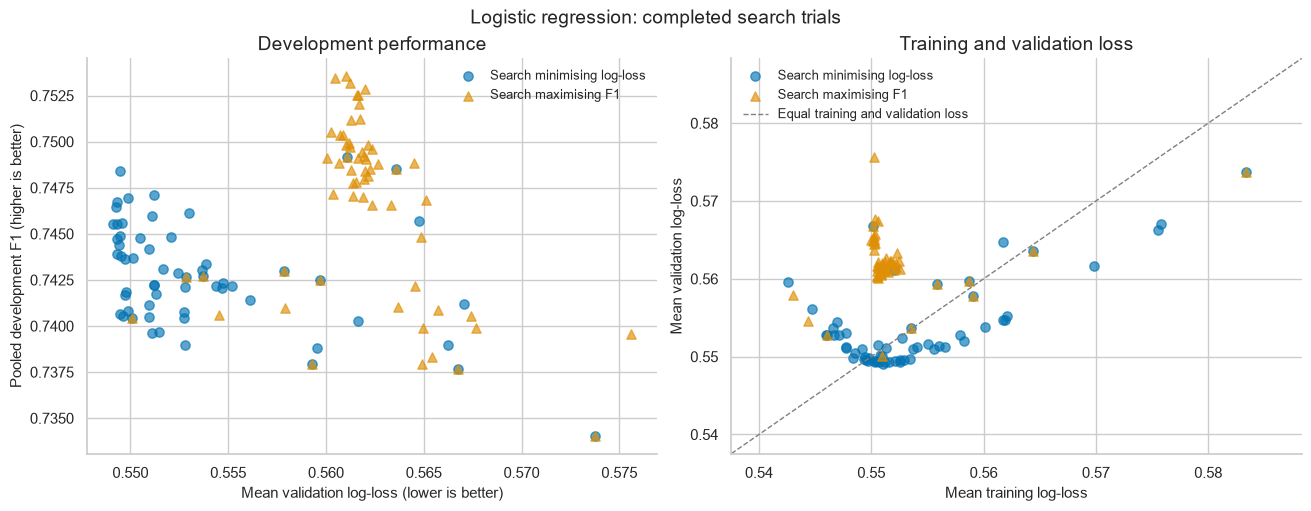

In [70]:
def plot_trials(studies, title=""):
    """Compare development metrics across completed search trials."""
    fig, axes = plt.subplots(
        1, 2,
        figsize=(13, 5),
        constrained_layout=True,
    )
    ax_left, ax_right = axes

    markers = ["o", "^", "s", "D"]
    colours = sns.color_palette(
        "colorblind",
        n_colors=len(studies),
    )
    loss_values = []

    for i, (label, study) in enumerate(studies.items()):
        table = trials_table(study)

        if table.empty:
            continue

        style = {
            "color": colours[i],
            "marker": markers[i % len(markers)],
            "alpha": 0.65,
            "s": 45,
            "label": label,
        }

        ax_left.scatter(
            table["log_loss"],
            table["f1"],
            **style,
        )

        ax_right.scatter(
            table["train_log_loss"],
            table["log_loss"],
            **style,
        )

        loss_values.extend(table["train_log_loss"].tolist())
        loss_values.extend(table["log_loss"].tolist())

    ax_left.set(
        xlabel="Mean validation log-loss (lower is better)",
        ylabel="Pooled development F1 (higher is better)",
        title="Development performance",
    )

    if loss_values:
        lower = min(loss_values)
        upper = max(loss_values)
        padding = max((upper - lower) * 0.05, 0.005)
        limits = [lower - padding, upper + padding]

        ax_right.plot(
            limits,
            limits,
            linestyle="--",
            color="grey",
            linewidth=1,
            label="Equal training and validation loss",
        )
        ax_right.set_xlim(limits)
        ax_right.set_ylim(limits)

    ax_right.set(
        xlabel="Mean training log-loss",
        ylabel="Mean validation log-loss",
        title="Training and validation loss",
    )

    for ax in axes:
        ax.legend(frameon=False, fontsize=9)

    sns.despine(fig=fig)
    fig.suptitle(title, fontsize=14)

    return fig


tn.plot_trials = plot_trials

fig = tn.plot_trials(
    {
        "Search minimising log-loss": study_lin["log_loss"],
        "Search maximising F1": study_lin["f1"],
    },
    title="Logistic regression: completed search trials",
)
plt.show()

The five best completed trials from each search are re-evaluated and
compared with the starting pipeline.

Comparisons use paired predictions for the same observations. Bootstrap
samples resample whole customers and retain each candidate’s selected
development threshold.

A candidate passes the exploratory improvement rule when its 95%
bootstrap interval for the F1 difference lies above zero and it performs
worse in no more than one fold.

If several candidates pass, the highest observed pooled F1 becomes the
comparison reference. A candidate with fewer columns may be preferred
when its comparison interval includes zero and it performs worse in no
more than two folds. This simplicity preference does not establish
equivalent performance.

The intervals are conditional on the fitted predictions and selected
thresholds. They do not capture all uncertainty from searching many
configurations or selecting thresholds.

In [71]:
def fast_f1(y, predicted):
    """F1 for boolean arrays."""
    y = np.asarray(y, dtype=bool)
    predicted = np.asarray(predicted, dtype=bool)

    tp = np.sum(y & predicted)
    fp = np.sum(~y & predicted)
    fn = np.sum(y & ~predicted)
    denominator = 2 * tp + fp + fn

    return float(2 * tp / denominator) if denominator else 0.0


def check_prediction_alignment(reference, option):
    """Require paired predictions for the same rows and outcomes."""
    columns = ["fold", "ID", "customer_id", "y"]

    pd.testing.assert_frame_equal(
        reference[columns].reset_index(drop=True),
        option[columns].reset_index(drop=True),
    )

    if reference["ID"].duplicated().any():
        raise ValueError("Prediction IDs must be unique.")

    if reference["customer_id"].isna().any():
        raise ValueError("Customer IDs must not be missing.")

    checked_probabilities(reference["p"], len(reference))
    checked_probabilities(option["p"], len(option))


def bootstrap_f1_diff(
    oof_ref,
    oof_opt,
    thr_ref,
    thr_opt,
    n_boot=2000,
    seed=RANDOM_STATE,
):
    """Customer-bootstrap interval for F1(option) - F1(reference)."""
    check_prediction_alignment(oof_ref, oof_opt)

    if n_boot < 1:
        raise ValueError("n_boot must be positive.")

    y = oof_ref["y"].to_numpy(dtype=bool)
    pred_ref = oof_ref["p"].to_numpy() >= thr_ref
    pred_opt = oof_opt["p"].to_numpy() >= thr_opt

    groups = list(
        oof_ref.groupby("customer_id", sort=False).indices.values()
    )

    if not groups:
        raise ValueError("No customers available for bootstrapping.")

    rng = np.random.default_rng(seed)
    differences = np.empty(n_boot)

    for b in range(n_boot):
        selected = rng.integers(
            0, len(groups), size=len(groups)
        )
        positions = np.concatenate([
            groups[i] for i in selected
        ])

        differences[b] = (
            fast_f1(y[positions], pred_opt[positions])
            - fast_f1(y[positions], pred_ref[positions])
        )

    return np.percentile(differences, [2.5, 97.5])


def judge(runs, reference, tie_rule=False):
    """Apply the exploratory improvement and simplicity rules."""
    ref_table, ref_oof, ref_threshold = runs[reference]

    ref_f1 = fast_f1(
        ref_oof["y"],
        ref_oof["p"].to_numpy() >= ref_threshold,
    )
    ref_features = ref_table["n_features"].mean()

    rows = []

    for name, (table, oof, threshold) in runs.items():
        check_prediction_alignment(ref_oof, oof)

        if not table.index.equals(ref_table.index):
            raise ValueError("Fold indices differ between candidates.")

        pooled_f1 = fast_f1(
            oof["y"],
            oof["p"].to_numpy() >= threshold,
        )
        n_features = table["n_features"].mean()
        folds_worse = int(
            (table["f1"] < ref_table["f1"]).sum()
        )

        if name == reference:
            lo, hi = np.nan, np.nan
            verdict = "reference"
        else:
            lo, hi = bootstrap_f1_diff(
                ref_oof,
                oof,
                ref_threshold,
                threshold,
            )

            if lo > 0 and folds_worse <= 1:
                verdict = "better"
            elif hi < 0:
                verdict = "worse"
            elif (
                tie_rule
                and lo <= 0 <= hi
                and n_features < ref_features
                and folds_worse <= 2
            ):
                verdict = (
                    "no clear difference; fewer columns preferred"
                )
            else:
                verdict = "no clear difference"

        rows.append({
            "option": name,
            "n_features": n_features,
            "f1_stacked": pooled_f1,
            "f1_diff": pooled_f1 - ref_f1,
            "ci_low": lo,
            "ci_high": hi,
            "folds_worse": folds_worse,
            "threshold": threshold,
            "log_loss": table["log_loss"].mean(),
            "ll_gain": table["ll_gain"].mean(),
            "roc_auc": table["roc_auc"].mean(),
            "verdict": verdict,
        })

    return pd.DataFrame(rows).set_index("option")


def choose_winner(runs, reference="base"):
    """Keep the reference unless a candidate passes the improvement rule."""
    comparison = judge(runs, reference)

    better = comparison.index[
        comparison["verdict"] == "better"
    ].tolist()

    if not better:
        return reference, comparison, None

    # Highest observed F1; use the name to resolve exact ties.
    best = sorted(
        better,
        key=lambda name: (
            -comparison.loc[name, "f1_stacked"],
            name,
        ),
    )[0]

    finalists = {name: runs[name] for name in better}
    finalist_comparison = judge(
        finalists,
        reference=best,
        tie_rule=True,
    )

    preferred = finalist_comparison.index[
        finalist_comparison["verdict"]
        == "no clear difference; fewer columns preferred"
    ].tolist()

    eligible = [best] + preferred

    chosen = sorted(
        eligible,
        key=lambda name: (
            finalist_comparison.loc[name, "n_features"],
            -finalist_comparison.loc[name, "f1_stacked"],
            name,
        ),
    )[0]

    return chosen, comparison, finalist_comparison


def top_params(study, k=5):
    """Parameters of the top completed trials."""
    table = trials_table(study)

    if table.empty:
        raise ValueError("The study has no completed trials.")

    trials_by_number = {
        trial.number: trial for trial in study.trials
    }

    return {
        int(number): dict(trials_by_number[int(number)].params)
        for number in table.head(k).index
    }


def rescore(params_by_trial, get_cache, make_model, prefix=""):
    """Re-evaluate shortlisted trials using the local scoring helpers."""
    runs = {}

    for number, params in params_by_trial.items():
        with warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)

            runs[f"{prefix}{number}"] = evaluate_cached(
                get_cache(params),
                make_model(params),
            )

    return runs


def chosen_params(chosen, studies):
    """Recover selected parameters; the starting pipeline uses defaults."""
    if chosen == "base":
        return {}

    objective, number = chosen.rsplit("_trial_", 1)

    trials_by_number = {
        trial.number: trial
        for trial in studies[objective].trials
    }

    return dict(trials_by_number[int(number)].params)


ev.bootstrap_f1_diff = bootstrap_f1_diff
ev.judge = judge
ev.choose_winner = choose_winner

tn.top_params = top_params
tn.rescore = rescore
tn.chosen_params = chosen_params


# Re-evaluate the top five trials from each search.
candidates = {}

for objective, study in study_lin.items():
    candidates.update(
        tn.rescore(
            tn.top_params(study, k=5),
            get_linear_cache,
            make_linear,
            prefix=f"{objective}_trial_",
        )
    )

runs_lin = {
    "base": start_runs["logistic"],
    **candidates,
}

chosen_lin, table_lin, table_lin_better = ev.choose_winner(
    runs_lin,
    reference="base",
)

display(table_lin)

if table_lin_better is not None:
    print("Comparison among candidates passing the improvement rule:")
    display(table_lin_better)

linear_params = tn.chosen_params(chosen_lin, study_lin)

print(f"Chosen linear configuration: {chosen_lin}")
print(f"Selected parameters: {linear_params}")

,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base,20.000,0.750,0.000,NaN,NaN,0,0.340,0.561,0.128,0.784,reference
log_loss_trial_54,14.500,0.746,-0.005,-0.016,0.008,3,0.330,0.549,0.140,0.781,no clear difference
log_loss_trial_55,15.250,0.746,-0.004,-0.014,0.009,2,0.330,0.549,0.140,0.782,no clear difference
log_loss_trial_56,14.500,0.745,-0.006,-0.017,0.007,3,0.340,0.549,0.140,0.781,no clear difference
log_loss_trial_51,15.750,0.746,-0.005,-0.015,0.007,2,0.340,0.549,0.140,0.782,no clear difference
log_loss_trial_42,15.750,0.744,-0.007,-0.017,0.006,2,0.320,0.549,0.140,0.782,no clear difference
f1_trial_42,21.250,0.754,0.003,-0.002,0.010,2,0.320,0.561,0.128,0.785,no clear difference
f1_trial_26,21.250,0.753,0.003,-0.003,0.011,1,0.320,0.560,0.128,0.785,no clear difference
f1_trial_54,21.250,0.753,0.003,-0.002,0.010,2,0.320,0.561,0.128,0.785,no clear difference


Chosen linear configuration: base
Selected parameters: {}


The starting logistic-regression pipeline is retained because none of
the ten shortlisted candidates passed the exploratory F1 improvement
rule.

The log-loss search reduced mean validation log-loss from approximately
0.561 to 0.549. Its shortlisted candidates used log transformations and
stronger regularisation, with pooled F1 values of approximately
0.744–0.746. Lower log-loss alone does not establish better calibration.

The F1 search reached approximately 0.754, compared with 0.750 for the
starting pipeline. However, all customer-bootstrap intervals for the
F1 differences included zero. The results therefore do not provide
clear evidence of an F1 improvement under the stated rule.

These intervals are conditional on the selected thresholds and
predictions and do not account for the full search process. The
starting pipeline remains the linear candidate for the subsequent
model comparison.

In [72]:
best_ll = tn.trials_table(study_lin["log_loss"]).iloc[0]
best_f1 = tn.trials_table(study_lin["f1"]).iloc[0]
base_row = table_lin.loc["base"]

completed_counts = {
    objective: sum(
        trial.state == optuna.trial.TrialState.COMPLETE
        for trial in study.trials
    )
    for objective, study in study_lin.items()
}

n_better = int((table_lin["verdict"] == "better").sum())
n_candidates = len(table_lin) - 1

log.record(
    "D31",
    "logistic regression settings",
    f"chosen: {chosen_lin}",
    (
        f"Completed trials: {completed_counts}. "
        f"Best log-loss search result: mean validation log-loss "
        f"{best_ll['log_loss']:.3f}, pooled F1 {best_ll['f1']:.3f}. "
        f"Best F1 search result: pooled F1 {best_f1['f1']:.3f}, "
        f"versus starting F1 {base_row['f1_stacked']:.3f}. "
        f"{n_better} of {n_candidates} shortlisted candidates passed "
        "the exploratory improvement rule. "
        "Retain the starting pipeline because none passed; "
        "intervals including zero do not establish equivalence."
    ),
    0,
    0,
    carries={
        "chosen": chosen_lin,
        "params": linear_params,
        "completed_trials": completed_counts,
        "best_log_loss_params": tn.top_params(
            study_lin["log_loss"], 1
        ),
        "best_f1_params": tn.top_params(
            study_lin["f1"], 1
        ),
    },
)

display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
32,D31,logistic regression settings,chosen: base,"Completed trials: {'log_loss': 60, 'f1': 60}. Best log-loss search result: mean validation log-l...",0,0


# 5. Gradient boosting

The starting histogram gradient-boosting model has a mean
training–validation log-loss gap of approximately 0.348. The search
tests whether different model settings improve development performance.

- **learning_rate** and **max_iter:** the contribution of each boosting
  iteration and the number of iterations. Their effects depend on
  each other.
- **max_leaf_nodes:** the maximum number of leaves in each tree.
- **min_samples_leaf:** the minimum number of training observations
  required in each leaf.
- **l2_regularization:** the penalty applied to leaf values.
- **max_features:** the proportion of features considered at each split.

The search includes configurations with different levels of complexity;
it does not assume that stronger regularisation always performs better.

Early stopping is disabled. The number of iterations is selected using
the explicit chronological folds rather than an internal random
validation split.

Two searches target 60 completed trials each: one minimises mean
validation log-loss and the other maximises pooled development F1.
The five best trials from each search are compared with the starting
pipeline using the same exploratory rule as the linear branch.

All candidates use the same 38 transformed inputs. Feature count
therefore does not distinguish their complexity. The holdout remains
excluded from tuning and candidate selection.

In [73]:
def suggest_tree(trial):
    """Settings tried for the tree branch: all of them make the trees more or less cautious."""
    return {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_iter": trial.suggest_int("max_iter", 50, 800, log=True),
        "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 4, 64, log=True),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 10, 300, log=True),
        "l2_regularization": trial.suggest_float("l2_regularization", 1e-3, 30, log=True),
        "max_features": trial.suggest_float("max_features", 0.3, 1.0),
    }

def get_tree_cache(params):
    return tree_cache  # the tree preprocessing has no tuned settings

def make_tree(params):
    """Gradient boosting on the cached tree matrix (small categories first)."""
    return HistGradientBoostingClassifier(
        **params,
        categorical_features=list(range(n_tree_cats)),
        early_stopping=False,  
        random_state=RANDOM_STATE,
    )

In [74]:
study_tree = {
    "log_loss": tn.tune(
        get_tree_cache,
        make_tree,
        suggest_tree,
        objective="log_loss",
        n_trials=N_TRIALS,
        seed=RANDOM_STATE,
        name="hist_gb_log_loss",
        storage=STORAGE,
        fresh=FRESH_SEARCH,
    ),
    "f1": tn.tune(
        get_tree_cache,
        make_tree,
        suggest_tree,
        objective="f1",
        n_trials=N_TRIALS,
        seed=RANDOM_STATE,
        name="hist_gb_f1",
        storage=STORAGE,
        fresh=FRESH_SEARCH,
    ),
}

show_tree = [
    "learning_rate",
    "max_iter",
    "max_leaf_nodes",
    "min_samples_leaf",
    "l2_regularization",
    "max_features",
    "n_features",
    "log_loss",
    "f1",
    "threshold",
    "roc_auc",
    "train_log_loss",
    "overfit_gap",
    "converged",
]

for objective, study in study_tree.items():
    print(f"\nSteered by {objective}")
    display(tn.trials_table(study).head(5)[show_tree])

hist_gb_log_loss: 60 completed trials; 0 additional trials requested.
hist_gb_f1: 60 completed trials; 0 additional trials requested.

Steered by log_loss


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,max_features,n_features,log_loss,f1,threshold,roc_auc,train_log_loss,overfit_gap,converged
trial,,,,,,,,,,,,,,
35,0.016,393,7,228,0.045,0.806,38.000,0.545,0.749,0.360,0.786,0.504,0.041,True
50,0.018,394,5,114,0.001,0.508,38.000,0.545,0.748,0.370,0.786,0.515,0.030,True
59,0.019,386,4,112,0.001,0.532,38.000,0.546,0.747,0.360,0.786,0.524,0.022,True
20,0.019,382,5,108,0.008,0.709,38.000,0.546,0.748,0.350,0.785,0.513,0.034,True
26,0.019,415,6,90,0.004,0.548,38.000,0.546,0.749,0.370,0.786,0.500,0.046,True



Steered by f1


,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,max_features,n_features,log_loss,f1,threshold,roc_auc,train_log_loss,overfit_gap,converged
trial,,,,,,,,,,,,,,
44,0.027,60,15,65,0.001,0.395,38.000,0.562,0.753,0.440,0.784,0.531,0.032,True
17,0.018,57,25,29,0.003,0.497,38.000,0.579,0.753,0.450,0.782,0.538,0.041,True
43,0.018,79,18,57,0.004,0.415,38.000,0.565,0.752,0.430,0.786,0.531,0.034,True
53,0.030,58,26,44,0.001,0.439,38.000,0.561,0.751,0.420,0.783,0.497,0.064,True
6,0.028,65,26,43,0.004,0.647,38.000,0.559,0.751,0.410,0.782,0.492,0.067,True


The charts show search progress, estimated hyperparameter importance
and the relationship between development F1 and log-loss.

Training and validation losses help assess how closely each candidate
fits its training data relative to later observations. A smaller gap
alone does not establish better generalisation; validation performance
must also be considered.

In [75]:
for objective, study in study_tree.items():
    plot_optimization_history(study).update_layout(title=f"Gradient boosting, steered by {objective}").show()
    plot_param_importances(study).update_layout(title=f"Which settings mattered, steered by {objective}").show()

plot_slice(study_tree["log_loss"]).update_layout(title="Log-loss against each setting").show()

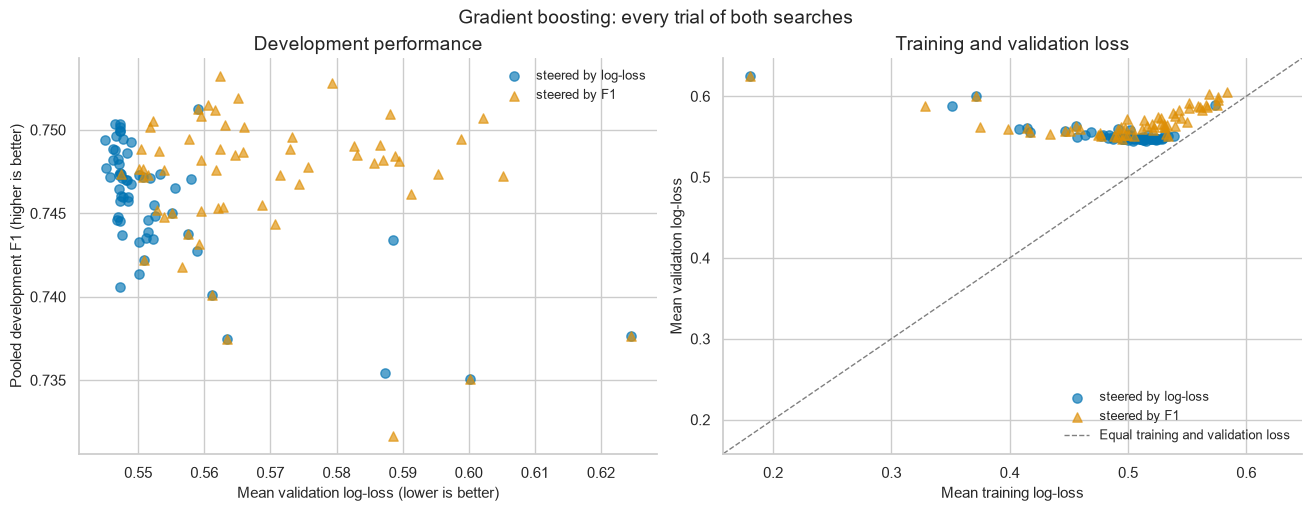

In [76]:
fig = tn.plot_trials(
    {"steered by log-loss": study_tree["log_loss"], "steered by F1": study_tree["f1"]},
    title="Gradient boosting: every trial of both searches",
)
plt.show()

The five best trials of each search are re-scored and compared with the untuned pipeline using the decision rule.

In [77]:
# Re-evaluate the top five completed trials from each search.
tree_candidates = {}

for objective, study in study_tree.items():
    tree_candidates.update(
        tn.rescore(
            tn.top_params(study, k=5),
            get_tree_cache,
            make_tree,
            prefix=f"{objective}_trial_",
        )
    )

runs_tree = {
    "base": start_runs["hist_gb"],
    **tree_candidates,
}

chosen_tree, table_tree, table_tree_better = ev.choose_winner(
    runs_tree,
    reference="base",
)

display(table_tree)

if table_tree_better is not None:
    print("Comparison among candidates passing the improvement rule:")
    display(table_tree_better)

tree_params = tn.chosen_params(chosen_tree, study_tree)

print(f"Chosen tree configuration: {chosen_tree}")
print(f"Selected parameters: {tree_params}")

,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
base,38.000,0.736,0.000,NaN,NaN,0,0.300,0.607,0.082,0.760,reference
log_loss_trial_35,38.000,0.749,0.014,0.001,0.029,1,0.360,0.545,0.144,0.786,better
log_loss_trial_50,38.000,0.748,0.012,-0.001,0.027,1,0.370,0.545,0.144,0.786,no clear difference
log_loss_trial_59,38.000,0.747,0.012,-0.001,0.027,1,0.360,0.546,0.143,0.786,no clear difference
log_loss_trial_20,38.000,0.748,0.013,0.001,0.027,1,0.350,0.546,0.143,0.785,better
log_loss_trial_26,38.000,0.749,0.013,0.001,0.027,0,0.370,0.546,0.143,0.786,better
f1_trial_44,38.000,0.753,0.018,0.004,0.034,0,0.440,0.562,0.126,0.784,better
f1_trial_17,38.000,0.753,0.017,0.004,0.033,0,0.450,0.579,0.109,0.782,better
f1_trial_43,38.000,0.752,0.016,0.004,0.032,0,0.430,0.565,0.124,0.786,better


Comparison among candidates passing the improvement rule:


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
log_loss_trial_35,38.000,0.749,-0.004,-0.011,0.005,3,0.360,0.545,0.144,0.786,no clear difference
log_loss_trial_20,38.000,0.748,-0.005,-0.015,0.006,3,0.350,0.546,0.143,0.785,no clear difference
log_loss_trial_26,38.000,0.749,-0.004,-0.013,0.004,3,0.370,0.546,0.143,0.786,no clear difference
f1_trial_44,38.000,0.753,0.000,NaN,NaN,0,0.440,0.562,0.126,0.784,reference
f1_trial_17,38.000,0.753,-0.000,-0.008,0.008,3,0.450,0.579,0.109,0.782,no clear difference
f1_trial_43,38.000,0.752,-0.001,-0.008,0.006,3,0.430,0.565,0.124,0.786,no clear difference
f1_trial_53,38.000,0.751,-0.002,-0.009,0.006,3,0.420,0.561,0.128,0.783,no clear difference
f1_trial_6,38.000,0.751,-0.002,-0.010,0.007,3,0.410,0.559,0.130,0.782,no clear difference


Chosen tree configuration: f1_trial_44
Selected parameters: {'learning_rate': 0.02718972457738439, 'max_iter': 60, 'max_leaf_nodes': 15, 'min_samples_leaf': 65, 'l2_regularization': 0.001256096474251964, 'max_features': 0.3954342777342081}


Eight of the ten shortlisted candidates passed the exploratory F1
improvement rule against the starting gradient-boosting pipeline.

The selected configuration is trial 44 from the F1 search. Its pooled
development F1 is approximately 0.753, compared with 0.736 for the
starting tree. The estimated difference is approximately +0.018, with
a customer-bootstrap interval of approximately [0.004, 0.034]. It is
worse in none of the four folds.

Its mean validation log-loss decreases from approximately 0.607 to
0.562, while ROC-AUC increases from 0.760 to 0.784. Its mean
training–validation log-loss gap decreases from 0.348 to approximately
0.032. These results suggest improved generalisation relative to the
starting configuration; they do not establish the absence of overfitting.

The log-loss search also finds candidates with lower validation
log-loss, approximately 0.545, but lower pooled F1 than trial 44.

All finalists use 38 transformed inputs. Trial 44 is retained because
it has the highest observed pooled F1 among candidates passing the
improvement rule. Comparisons with the other finalists do not establish
that it is uniquely superior.

The selected tree will next be compared with the retained logistic
regression using development predictions. The holdout has not been
used in this selection.

In [78]:
winners = table_tree.loc[
    table_tree["verdict"] == "better"
]

selected_tree_row = table_tree.loc[chosen_tree]
base_tree_row = table_tree.loc["base"]

completed_tree_counts = {
    objective: sum(
        trial.state == optuna.trial.TrialState.COMPLETE
        for trial in study.trials
    )
    for objective, study in study_tree.items()
}

log.record(
    "D32",
    "gradient boosting settings",
    f"chosen: {chosen_tree}",
    (
        f"Completed trials: {completed_tree_counts}. "
        f"{len(winners)} of {len(table_tree) - 1} shortlisted "
        "candidates passed the exploratory improvement rule. "
        f"Selected pooled F1 {selected_tree_row['f1_stacked']:.3f} "
        f"versus starting F1 {base_tree_row['f1_stacked']:.3f}. "
        f"Selected mean validation log-loss "
        f"{selected_tree_row['log_loss']:.3f}. "
        "The selected candidate has the highest observed pooled F1 "
        "among those passing the rule; finalist comparisons do not "
        "establish unique superiority. Holdout excluded from selection."
    ),
    0,
    0,
    carries={
        "chosen": chosen_tree,
        "params": tree_params,
        "completed_trials": completed_tree_counts,
        "best_log_loss_params": tn.top_params(
            study_tree["log_loss"], 1
        ),
    },
)

display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
33,D32,gradient boosting settings,chosen: f1_trial_44,"Completed trials: {'log_loss': 60, 'f1': 60}. 8 of 10 shortlisted candidates passed the explorat...",0,0


# 6. Model choice and threshold

## 6.1. Choosing the model

Three candidates are compared using predictions for the same development
observations: the retained logistic regression, the selected gradient
boosting model and an equal-weight average of their probabilities.

The blend uses fixed weights of 0.5 and 0.5. Its threshold is selected
from its own pooled development predictions using the same threshold
rule as the individual models.

Logistic regression remains the reference because it is the simpler
model to interpret. The tree replaces it only if it passes the
exploratory F1 improvement rule. The blend is selected only if it passes
that rule against the selected single model.

These comparisons remain part of development selection. The holdout
is excluded. For the blend, the reported feature count is the sum of
the component models’ feature counts, not a count of unique inputs.

In [79]:
def blend_runs(runs, weights=None):
    """Average paired probabilities and score the resulting blend."""
    names = list(runs)

    if len(names) < 2:
        raise ValueError("A blend requires at least two models.")

    if weights is None:
        weights = np.ones(len(names), dtype=float)
    else:
        weights = np.asarray(weights, dtype=float)

    if (
        weights.shape != (len(names),)
        or not np.isfinite(weights).all()
        or (weights < 0).any()
        or weights.sum() <= 0
    ):
        raise ValueError(
            "Provide one finite, non-negative weight per model, "
            "with a positive total."
        )

    weights = weights / weights.sum()

    reference_table, reference_oof, _ = runs[names[0]]

    for name in names[1:]:
        table, oof, _ = runs[name]

        check_prediction_alignment(reference_oof, oof)

        if not table.index.equals(reference_table.index):
            raise ValueError("Component fold indices differ.")

        np.testing.assert_array_equal(
            table["train_rows"],
            reference_table["train_rows"],
        )
        np.testing.assert_allclose(
            table["ll_floor"],
            reference_table["ll_floor"],
            rtol=1e-10,
            atol=1e-12,
        )

    oof = reference_oof[
        ["fold", "ID", "customer_id", "y"]
    ].copy()

    component_probabilities = np.column_stack([
        runs[name][1]["p"].to_numpy()
        for name in names
    ])

    oof["p"] = checked_probabilities(
        component_probabilities @ weights,
        len(oof),
    )

    blend_threshold, _, _ = best_threshold(
        oof["y"],
        oof["p"],
    )

    rows = []

    for year in reference_table.index:
        part = oof.loc[oof["fold"] == year]
        y = part["y"].to_numpy()
        p = part["p"].to_numpy()

        loss = log_loss(y, p, labels=[0, 1])
        baseline_loss = reference_table.loc[year, "ll_floor"]
        score = f1_score(
            y,
            p >= blend_threshold,
            zero_division=0,
        )
        floor = f1_floor(y)

        rows.append({
            "fold": year,
            "train_rows": reference_table.loc[year, "train_rows"],
            # Total component columns, including any shared inputs.
            "n_features": sum(
                runs[name][0].loc[year, "n_features"]
                for name in names
            ),
            "log_loss": loss,
            "ll_floor": baseline_loss,
            "ll_gain": baseline_loss - loss,
            "roc_auc": (
                roc_auc_score(y, p)
                if np.unique(y).size == 2
                else np.nan
            ),
            "f1": score,
            "floor": floor,
            "lift": score - floor,
        })

    return (
        pd.DataFrame(rows).set_index("fold"),
        oof,
        blend_threshold,
    )


ev.blend_runs = blend_runs

REFERENCE = "logistic"

runs_choice = {
    "logistic": runs_lin[chosen_lin],
    "hist_gb_tuned": runs_tree[chosen_tree],
}

runs_choice["blend_50_50"] = ev.blend_runs({
    "logistic": runs_choice["logistic"],
    "hist_gb_tuned": runs_choice["hist_gb_tuned"],
})

# Step 1: compare the tree with the linear reference.
table_choice = ev.judge(
    {
        REFERENCE: runs_choice[REFERENCE],
        "hist_gb_tuned": runs_choice["hist_gb_tuned"],
    },
    reference=REFERENCE,
)

print("Single-model comparison:")
display(table_choice)

single = (
    "hist_gb_tuned"
    if table_choice.loc["hist_gb_tuned", "verdict"] == "better"
    else REFERENCE
)

# Step 2: the blend must pass the rule against the selected single model.
table_blend = ev.judge(
    {
        single: runs_choice[single],
        "blend_50_50": runs_choice["blend_50_50"],
    },
    reference=single,
)

print("Blend comparison:")
display(table_blend)

chosen_model = (
    "blend_50_50"
    if table_blend.loc["blend_50_50", "verdict"] == "better"
    else single
)

threshold = runs_choice[chosen_model][2]

print(f"Chosen model: {chosen_model}")
print(f"Development-selected threshold: {threshold:.3f}")

Single-model comparison:


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
logistic,20.000,0.750,0.000,NaN,NaN,0,0.340,0.561,0.128,0.784,reference
hist_gb_tuned,38.000,0.753,0.003,-0.008,0.015,1,0.440,0.562,0.126,0.784,no clear difference


Blend comparison:


,n_features,f1_stacked,f1_diff,ci_low,ci_high,folds_worse,threshold,log_loss,ll_gain,roc_auc,verdict
option,,,,,,,,,,,
logistic,20.000,0.750,0.000,NaN,NaN,0,0.340,0.561,0.128,0.784,reference
blend_50_50,58.000,0.755,0.004,-0.003,0.013,1,0.380,0.548,0.140,0.789,no clear difference


Chosen model: logistic
Development-selected threshold: 0.340


Logistic regression is retained under the predefined selection rule.

The tuned tree achieves pooled development F1 of approximately 0.753,
compared with 0.750 for logistic regression. Its F1 difference has a
customer-bootstrap interval of approximately [-0.008, 0.015], so it
does not pass the exploratory improvement rule.

The equal-weight blend achieves pooled F1 of approximately 0.755.
Its comparison interval against logistic regression is approximately
[-0.003, 0.013], which also includes zero.

The blend has lower observed mean validation log-loss (0.548) and
higher mean ROC-AUC (0.789). However, neither alternative provides
clear evidence of an F1 improvement under the stated rule. These
results do not establish equivalent performance.

The retained model is logistic regression with its starting
configuration and development-selected threshold of 0.340.

In [80]:
tree_row = table_choice.loc["hist_gb_tuned"]
blend_row = table_blend.loc["blend_50_50"]

log.record(
    "D33",
    "final model",
    f"retain {chosen_model}",
    (
        f"Tuned tree versus {REFERENCE}: "
        f"F1 difference {tree_row['f1_diff']:+.3f}, "
        f"95% customer-bootstrap interval "
        f"[{tree_row['ci_low']:.3f}, {tree_row['ci_high']:.3f}]; "
        f"{tree_row['verdict']}. "
        f"Blend versus {single}: "
        f"F1 difference {blend_row['f1_diff']:+.3f}, "
        f"interval "
        f"[{blend_row['ci_low']:.3f}, {blend_row['ci_high']:.3f}]; "
        f"{blend_row['verdict']}. "
        f"Retain development-selected threshold {threshold:.3f}. "
        "Neither alternative passed the exploratory improvement rule; "
        "this does not establish equivalent performance."
    ),
    0,
    0,
    carries={
        "chosen": chosen_model,
        "threshold": float(threshold),
        "candidates": list(runs_choice),
        "linear_params": linear_params,
        "tree_params": tree_params,
    },
)

display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
34,D33,final model,retain logistic,"Tuned tree versus logistic: F1 difference +0.003, 95% customer-bootstrap interval [-0.008, 0.015...",0,0


## 6.2. Threshold sensitivity across validation years

The threshold is selected using the pooled predictions from the four
development folds and is now fixed.

The chart compares the pooled F1 curve with each validation year’s
curve. The table distinguishes the maximum F1 on the tested grid from
F1 at the threshold selected by our near-best-range rule.

Year-specific thresholds are descriptive diagnostics only. They are
not used to change the fixed threshold. Differences between years
may reflect changes in customer mix, outcomes and model performance;
the curves alone cannot establish robustness to future drift.

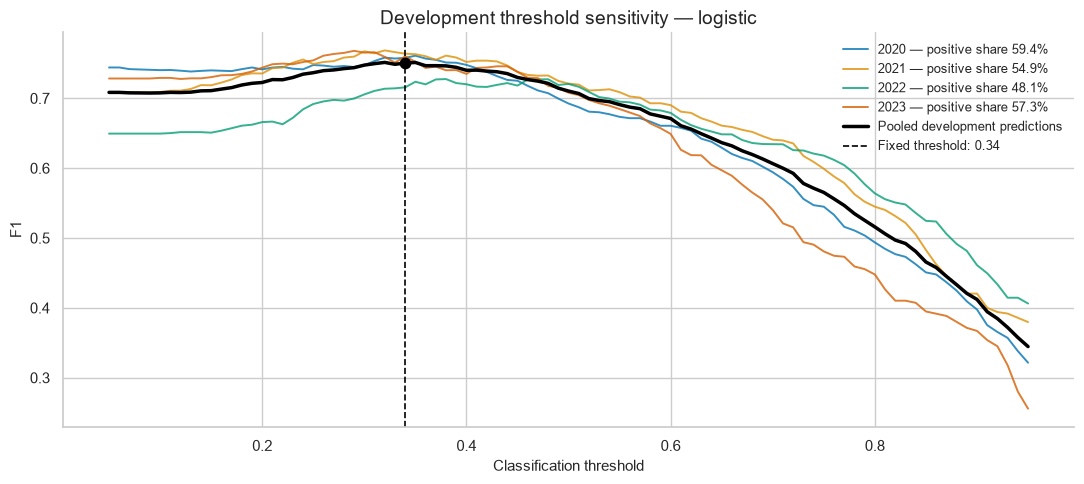

,observations,positive_share,year_selected_threshold,f1_at_year_selected_threshold,grid_max_f1,f1_at_fixed_threshold,gap_to_year_grid_max
fold,,,,,,,
2020,670,0.594,0.340,0.758,0.761,0.758,0.003
2021,782,0.549,0.320,0.769,0.769,0.764,0.005
2022,628,0.481,0.370,0.727,0.728,0.716,0.012
2023,536,0.573,0.290,0.768,0.768,0.760,0.008


Fixed development threshold: 0.340
Pooled F1 at this threshold: 0.7505
Maximum pooled F1 on the grid: 0.7514


In [81]:
oof_chosen = runs_choice[chosen_model][1]

fig, ax = plt.subplots(figsize=(11, 5))
rows = []

for year, part in oof_chosen.groupby("fold", sort=True):
    year_threshold, grid, f1s = best_threshold(
        part["y"],
        part["p"],
    )

    year_selected_f1 = f1_score(
        part["y"],
        part["p"] >= year_threshold,
        zero_division=0,
    )
    fixed_f1 = f1_score(
        part["y"],
        part["p"] >= threshold,
        zero_division=0,
    )

    ax.plot(
        grid,
        f1s,
        linewidth=1.4,
        alpha=0.8,
        label=f"{year} — positive share {part['y'].mean():.1%}",
    )

    rows.append({
        "fold": year,
        "observations": len(part),
        "positive_share": part["y"].mean(),
        "year_selected_threshold": year_threshold,
        "f1_at_year_selected_threshold": year_selected_f1,
        "grid_max_f1": float(f1s.max()),
        "f1_at_fixed_threshold": fixed_f1,
        "gap_to_year_grid_max": float(f1s.max()) - fixed_f1,
    })

pooled_threshold, grid, pooled_f1s = best_threshold(
    oof_chosen["y"],
    oof_chosen["p"],
)

np.testing.assert_allclose(
    pooled_threshold,
    threshold,
    rtol=0,
    atol=1e-12,
)

pooled_selected_f1 = f1_score(
    oof_chosen["y"],
    oof_chosen["p"] >= threshold,
    zero_division=0,
)

ax.plot(
    grid,
    pooled_f1s,
    color="black",
    linewidth=2.5,
    label="Pooled development predictions",
)
ax.axvline(
    threshold,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label=f"Fixed threshold: {threshold:.2f}",
)
ax.scatter(
    [threshold],
    [pooled_selected_f1],
    color="black",
    s=55,
    zorder=5,
)

ax.set(
    xlabel="Classification threshold",
    ylabel="F1",
    title=f"Development threshold sensitivity — {chosen_model}",
)
ax.legend(frameon=False, fontsize=9)
sns.despine()
plt.tight_layout()
plt.show()

threshold_table = pd.DataFrame(rows).set_index("fold")
display(threshold_table)

print(f"Fixed development threshold: {threshold:.3f}")
print(f"Pooled F1 at this threshold: {pooled_selected_f1:.4f}")
print(f"Maximum pooled F1 on the grid: {pooled_f1s.max():.4f}")

The fixed development threshold is 0.340. Its pooled F1 is 0.7505,
compared with a maximum of 0.7514 on the tested grid. The small
difference follows from selecting a central threshold within the
near-best range rather than requiring the exact grid maximum.

Year-specific selected thresholds range from 0.290 to 0.370. At the
fixed threshold, yearly F1 is approximately 0.003–0.012 below each
year’s grid maximum. The largest difference occurs in 2022, which
also has the lowest observed positive share.

These are descriptive development results. They do not establish
that changes in the positive share caused the threshold differences
or guarantee robustness to future drift.

The threshold remains fixed at 0.340 for holdout evaluation and
subsequent test predictions.

# 7. Holdout assessment

The selected model is fitted on the development set and evaluated on
purchases from January 2024 to February 2025. Its settings and threshold
remain fixed from development selection.

Results are also reported separately for customers seen and unseen in
development. Unseen customers may still have historical purchase
information in the supplied features.

This period has already been inspected in earlier notebook versions,
so this assessment should not be described as a newly untouched test.
Its results are not used here to change the model or threshold.

In [82]:
def fit_predict(model_name, fit_rows, predict_rows):
    """Fit the selected pipelines and return checked probabilities."""
    allowed = {"logistic", "hist_gb_tuned", "blend_50_50"}

    if model_name not in allowed:
        raise ValueError(f"Unknown model: {model_name}")

    if fit_rows.empty or predict_rows.empty:
        raise ValueError("Training and prediction rows must be non-empty.")

    if fit_rows[target].nunique() != 2:
        raise ValueError("Training rows must contain both target classes.")

    predictions = {}

    with warnings.catch_warnings():
        warnings.simplefilter("error", ConvergenceWarning)

        if model_name in {"logistic", "blend_50_50"}:
            log_transform = (
                FoldLog1p(
                    threshold=1.0,
                    exclude=NOISE + ["customer_since_year"],
                )
                if linear_params.get("use_log", False)
                else None
            )

            linear_pipe = build_linear_pipeline(
                LogisticRegression(
                    C=linear_params.get("model_C", 1.0),
                    max_iter=5000,
                    random_state=RANDOM_STATE,
                ),
                roles,
                enet_c=linear_params.get(
                    "select_C",
                    config["linear"]["selector_C"],
                ),
                enet_l1_ratio=linear_params.get(
                    "l1_ratio",
                    config["linear"]["selector_l1_ratio"],
                ),
                log_transform=log_transform,
            )

            linear_pipe.fit(
                fit_rows[linear_inputs],
                fit_rows[target],
            )

            predictions["logistic"] = checked_probabilities(
                linear_pipe.predict_proba(
                    predict_rows[linear_inputs]
                )[:, 1],
                len(predict_rows),
            )

        if model_name in {"hist_gb_tuned", "blend_50_50"}:
            tree_pipe = build_tree_pipeline(
                HistGradientBoostingClassifier(
                    **tree_params,
                    early_stopping=False,
                    random_state=RANDOM_STATE,
                ),
                roles,
            )

            tree_pipe.fit(
                fit_rows[tree_inputs],
                fit_rows[target],
            )

            predictions["hist_gb_tuned"] = checked_probabilities(
                tree_pipe.predict_proba(
                    predict_rows[tree_inputs]
                )[:, 1],
                len(predict_rows),
            )

    return checked_probabilities(
        np.mean(
            np.column_stack(list(predictions.values())),
            axis=1,
        ),
        len(predict_rows),
    )

,rows,customers,positive_share,f1,f1_floor,precision,recall,log_loss,roc_auc,predicted_positive_share,lift
group,,,,,,,,,,,
all rows,835,215,0.605,0.781,0.754,0.716,0.859,0.564,0.782,0.726,0.028
seen customers,757,182,0.625,0.794,0.769,0.728,0.873,0.559,0.783,0.749,0.025
unseen customers,78,33,0.410,0.592,0.582,0.538,0.656,0.608,0.680,0.500,0.010


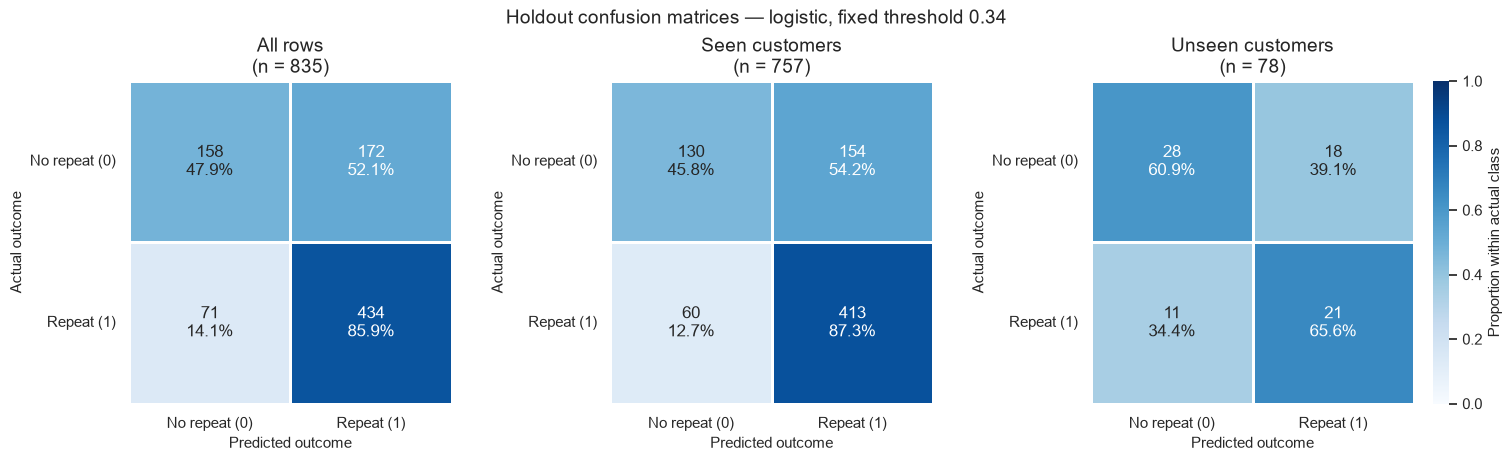

Fixed threshold used: 0.340
Annotations show counts and percentages within each actual class.
Holdout outcomes were not used to retune the threshold.


In [83]:
p_holdout = fit_predict(chosen_model, dev, holdout)
y_holdout = holdout[target].to_numpy()
pred_holdout = p_holdout >= threshold

seen = holdout["customer_id"].isin(
    dev["customer_id"]
).to_numpy()

groups = {
    "all rows": np.ones(len(holdout), dtype=bool),
    "seen customers": seen,
    "unseen customers": ~seen,
}

score_rows = []

for group, mask in groups.items():
    if not mask.any():
        continue

    y = y_holdout[mask]
    p = p_holdout[mask]
    predicted = pred_holdout[mask]

    score_rows.append({
        "group": group,
        "rows": int(mask.sum()),
        "customers": holdout.loc[mask, "customer_id"].nunique(),
        "positive_share": y.mean(),
        "f1": f1_score(y, predicted, zero_division=0),
        "f1_floor": f1_floor(y),
        "precision": precision_score(
            y, predicted, zero_division=0
        ),
        "recall": recall_score(
            y, predicted, zero_division=0
        ),
        "log_loss": log_loss(y, p, labels=[0, 1]),
        "roc_auc": (
            roc_auc_score(y, p)
            if np.unique(y).size == 2
            else np.nan
        ),
        "predicted_positive_share": predicted.mean(),
    })

holdout_scores = pd.DataFrame(score_rows).set_index("group")
holdout_scores["lift"] = (
    holdout_scores["f1"] - holdout_scores["f1_floor"]
)

display(holdout_scores)

# Confusion matrices: counts and percentages within each actual class.
active_groups = [
    (group, mask)
    for group, mask in groups.items()
    if mask.any()
]

fig, axes = plt.subplots(
    1,
    len(active_groups),
    figsize=(5 * len(active_groups), 4.5),
    squeeze=False,
    constrained_layout=True,
)

class_labels = ["No repeat (0)", "Repeat (1)"]

for i, (group, mask) in enumerate(active_groups):
    ax = axes[0, i]

    counts = confusion_matrix(
        y_holdout[mask],
        pred_holdout[mask],
        labels=[0, 1],
    )

    row_totals = counts.sum(axis=1, keepdims=True)
    proportions = np.divide(
        counts,
        row_totals,
        out=np.zeros_like(counts, dtype=float),
        where=row_totals != 0,
    )

    annotations = np.empty((2, 2), dtype=object)

    for actual in range(2):
        for predicted in range(2):
            percentage = (
                f"{proportions[actual, predicted]:.1%}"
                if row_totals[actual, 0] > 0
                else "N/A"
            )
            annotations[actual, predicted] = (
                f"{counts[actual, predicted]:,}\n{percentage}"
            )

    sns.heatmap(
        proportions,
        annot=annotations,
        fmt="",
        cmap="Blues",
        vmin=0,
        vmax=1,
        square=True,
        linewidths=1,
        xticklabels=class_labels,
        yticklabels=class_labels,
        cbar=i == len(active_groups) - 1,
        cbar_kws={"label": "Proportion within actual class"},
        ax=ax,
    )

    ax.set(
        xlabel="Predicted outcome",
        ylabel="Actual outcome",
        title=f"{group.capitalize()}\n(n = {mask.sum():,})",
    )
    ax.tick_params(axis="y", rotation=0)

fig.suptitle(
    f"Holdout confusion matrices — {chosen_model}, "
    f"fixed threshold {threshold:.2f}",
    fontsize=14,
)

plt.show()

print(f"Fixed threshold used: {threshold:.3f}")
print("Annotations show counts and percentages within each actual class.")
print("Holdout outcomes were not used to retune the threshold.")

At the fixed threshold of 0.340, logistic regression achieves holdout
F1 of approximately 0.781, compared with an always-positive baseline
of 0.754. Mean log-loss is approximately 0.564 and ROC-AUC is 0.782,
close to the corresponding development results.

Precision is approximately 0.716 and recall is 0.859. The model
identifies 434 of 505 repeat purchases, misses 71 and produces
172 false positives. It predicts a repeat for approximately 72.6%
of observations, compared with an observed positive share of 60.5%.

Performance is lower for customers unseen in development: F1 is
approximately 0.592, only 0.010 above their always-positive baseline.
This subgroup contains 78 observations from 33 customers, so its
results require caution. Unseen status does not necessarily mean
that the supplied purchase-history features are unavailable.

The assessment supports reporting performance on this later period,
but does not guarantee performance on the future test set. Model
settings and the threshold remain unchanged.

In [84]:
all_row = holdout_scores.loc["all rows"]
unseen_row = holdout_scores.loc["unseen customers"]

log.record(
    "D34",
    "holdout assessment",
    f"{chosen_model} evaluated at fixed threshold {threshold:.3f}",
    (
        f"F1 {all_row['f1']:.3f} versus always-positive baseline "
        f"{all_row['f1_floor']:.3f}; "
        f"log-loss {all_row['log_loss']:.3f}; "
        f"ROC-AUC {all_row['roc_auc']:.3f}; "
        f"precision {all_row['precision']:.3f}; "
        f"recall {all_row['recall']:.3f}. "
        f"Unseen customers: F1 {unseen_row['f1']:.3f}, "
        f"lift {unseen_row['lift']:.3f}, "
        f"{int(unseen_row['rows'])} observations from "
        f"{int(unseen_row['customers'])} customers. "
        "No model or threshold changes were made from these results. "
        "This period was also inspected in earlier notebook versions."
    ),
    0,
    len(holdout),
    carries={
        "threshold": float(threshold),
        "holdout_f1": float(all_row["f1"]),
        "holdout_log_loss": float(all_row["log_loss"]),
        "holdout_roc_auc": float(all_row["roc_auc"]),
    },
)

display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
35,D34,holdout assessment,logistic evaluated at fixed threshold 0.340,F1 0.781 versus always-positive baseline 0.754; log-loss 0.564; ROC-AUC 0.782; precision 0.716; ...,0,835


# 8. Final model and submission

## 8.1. Fixed submission threshold

The submission retains the development-selected threshold of 0.340.
Holdout labels are not used to select a new threshold.

The final pipeline will be refitted on all eligible labelled training
observations, including the gap and holdout rows. Learned preprocessing,
feature selection and model coefficients will be refitted using those
rows, while the selected configuration and threshold remain fixed.

The holdout assessment describes the model trained on development
data. It is not a separate evaluation of the final refitted model.

In [85]:
threshold_final = float(threshold)

np.testing.assert_allclose(
    threshold_final,
    runs_choice[chosen_model][2],
    rtol=0,
    atol=1e-12,
)

print(f"Final model configuration: {chosen_model}")
print(f"Fixed submission threshold: {threshold_final:.3f}")
print("Threshold source: pooled development predictions only.")

Final model configuration: logistic
Fixed submission threshold: 0.340
Threshold source: pooled development predictions only.


The submission threshold remains 0.340. Refitting the pipeline on all
eligible labelled rows does not trigger another threshold search.
The effect of refitting on future performance cannot be measured
without additional labelled evaluation data.

In [86]:
log.record(
    "D35",
    "decision threshold",
    f"retain development threshold {threshold_final:.3f}",
    (
        "The submission uses the threshold selected from the four "
        "development folds. Holdout outcomes were not added to the "
        "threshold search. The final pipeline will be refitted on all "
        "eligible labelled training rows with this threshold fixed."
    ),
    0,
    0,
    carries={
        "threshold_final": threshold_final,
        "threshold_four_folds": float(threshold),
        "threshold_source": "development OOF predictions only",
    },
)

display(log.to_frame().tail(1))

,step,column,action,reason,rows_train,rows_test
36,D35,decision threshold,retain development threshold 0.340,The submission uses the threshold selected from the four development folds. Holdout outcomes wer...,0,0


## 8.2. Final fit and test predictions

The selected pipeline is refitted on all eligible labelled purchases,
including development, gap and holdout observations. Preprocessing
and feature selection are fitted again using these training rows.
The configuration and threshold remain fixed.

Submission checks verify row counts, unique IDs, complete predictions,
sample-submission order and binary target values.

Predicted probabilities and positive shares are also compared with
the holdout descriptively. They are not required to match: the periods
contain different observations and use models fitted on different
training sets. Test outcomes are unavailable.

A separate diagnostic examines customers whose recorded start year
exceeds the maximum in training. A difference in their predictions
does not, by itself, establish an error or its cause.

In [87]:
id_col = "ID"
target_col = target

# Validate the expected submission schema before fitting.
assert len(sample_submission.columns) == 2, (
    "Expected an ID column and one prediction column."
)
assert set(sample_submission.columns) == {id_col, target_col}, (
    "Unexpected sample-submission columns."
)

for name, frame in {
    "training": train,
    "test": test,
    "sample submission": sample_submission,
}.items():
    assert frame[id_col].notna().all(), (
        f"{name}: missing IDs."
    )
    assert frame[id_col].is_unique, (
        f"{name}: duplicate IDs."
    )

assert len(test) == len(sample_submission)
assert set(test[id_col]) == set(sample_submission[id_col]), (
    "Test and sample-submission IDs differ."
)

# All training target windows must close before the test period.
assert (
    train["purchase_date"] + pd.Timedelta(days=GAP_DAYS)
).max() < test["purchase_date"].min(), (
    "A training outcome window reaches the test period."
)

# Refit using all eligible labelled rows.
p_test = checked_probabilities(
    fit_predict(chosen_model, train, test),
    len(test),
)
pred_test = (p_test >= threshold_final).astype(int)

predictions_by_id = pd.DataFrame({
    id_col: test[id_col].to_numpy(),
    target_col: pred_test,
})

# Match predictions by ID, preserving the sample-submission order.
submission = sample_submission[[id_col]].merge(
    predictions_by_id,
    on=id_col,
    how="left",
    sort=False,
    validate="one_to_one",
)

submission = submission.loc[:, sample_submission.columns]

assert len(submission) == len(sample_submission) == len(test)
pd.testing.assert_series_equal(
    submission[id_col].reset_index(drop=True),
    sample_submission[id_col].reset_index(drop=True),
    check_names=False,
)
assert submission[target_col].notna().all()
assert submission[target_col].isin([0, 1]).all()

submission[target_col] = submission[target_col].astype(int)

prediction_summary = pd.DataFrame({
    "holdout": {
        "observations": len(p_holdout),
        "mean_probability": p_holdout.mean(),
        "predicted_positive_share": pred_holdout.mean(),
    },
    "test": {
        "observations": len(p_test),
        "mean_probability": p_test.mean(),
        "predicted_positive_share": pred_test.mean(),
    },
}).T

display(prediction_summary)

# Used by the next diagnostic cell.
late_start = (
    test["customer_since_year"]
    > train["customer_since_year"].max()
).to_numpy()

print(f"Final refit used {len(train):,} labelled observations.")
print(f"Submission threshold: {threshold_final:.3f}")
print(
    f"Submission checks passed: {len(submission):,} rows, "
    "unique IDs, sample order and binary predictions."
)

,observations,mean_probability,predicted_positive_share
holdout,835.000,0.549,0.726
test,986.000,0.599,0.822


Final refit used 6,469 labelled observations.
Submission threshold: 0.340
Submission checks passed: 986 rows, unique IDs, sample order and binary predictions.


All submission checks pass: 986 observations, unique IDs in the sample
submission’s order and binary predictions.

The final model predicts repeats for approximately 82.2% of test
observations, compared with 72.6% on the holdout. Mean predicted
probability is approximately 0.599 for test and 0.549 for holdout.

These differences describe model predictions, not observed test
outcomes. They may reflect differences in the feature distributions
and the additional labelled rows used for the final refit. They do
not establish that the true repeat-purchase rate increased.

In [90]:
# Descriptive diagnostic only: do not change model selection or threshold.
new_in_test = ~test["customer_id"].isin(
    train["customer_id"]
).to_numpy()

new_holdout = ~seen

# Explicit model names prevent misleading probability-column labels.
p_test_linear = (
    p_test
    if chosen_model == "logistic"
    else fit_predict("logistic", train, test)
)

p_test_tree = (
    p_test
    if chosen_model == "hist_gb_tuned"
    else fit_predict("hist_gb_tuned", train, test)
)

p_holdout_linear = (
    p_holdout
    if chosen_model == "logistic"
    else fit_predict("logistic", dev, holdout)
)


def masked_mean(values, mask):
    """Return NaN when a diagnostic group is empty."""
    values = np.asarray(values)
    return float(values[mask].mean()) if mask.any() else np.nan


other_unseen = new_in_test & ~late_start

diag = pd.DataFrame({
    "rows": [
        int(late_start.sum()),
        int(other_unseen.sum()),
        int(new_holdout.sum()),
    ],
    "customers": [
        test.loc[late_start, "customer_id"].nunique(),
        test.loc[other_unseen, "customer_id"].nunique(),
        holdout.loc[new_holdout, "customer_id"].nunique(),
    ],
    "logistic_mean_p": [
        masked_mean(p_test_linear, late_start),
        masked_mean(p_test_linear, other_unseen),
        masked_mean(p_holdout_linear, new_holdout),
    ],
    "hist_gb_mean_p": [
        masked_mean(p_test_tree, late_start),
        masked_mean(p_test_tree, other_unseen),
        np.nan,
    ],
    "actual_repeat_share": [
        np.nan,
        np.nan,
        masked_mean(y_holdout, new_holdout),
    ],
}, index=[
    "test: start year above training maximum",
    "test: unseen customer, start year within training range",
    "holdout: unseen customer",
])

display(diag)

print(
    "Maximum recorded customer start year in training:",
    train["customer_since_year"].max(),
)
print(
    "Late-start test observations from customers seen in training:",
    int((late_start & ~new_in_test).sum()),
)
print(
    "Group differences are descriptive and do not identify "
    "the cause of the predictions."
)

,rows,customers,logistic_mean_p,hist_gb_mean_p,actual_repeat_share
test: start year above training maximum,41,19,0.282,0.414,NaN
"test: unseen customer, start year within training range",13,3,0.353,0.576,NaN
holdout: unseen customer,78,33,0.390,NaN,0.410


Maximum recorded customer start year in training: 2024
Late-start test observations from customers seen in training: 0
Group differences are descriptive and do not identify the cause of the predictions.


The 41 test observations whose customer start year exceeds the training
maximum belong to 19 customers unseen in training. Their mean predicted
probability is approximately 0.282 for logistic regression and 0.414
for gradient boosting.

The remaining unseen test customers contribute 13 observations from
three customers. Their corresponding means are approximately 0.353
and 0.576. These small groups differ in more than their start years,
so this comparison cannot separate start-year extrapolation from
other customer characteristics.

For unseen holdout customers, the logistic model’s mean probability
is approximately 0.390, compared with an observed repeat share of
0.410. Agreement at this aggregate level does not establish calibration
for individual customers or for the future test period.

This diagnostic does not change the selected model or threshold.

## 8.3. Saving the submission and logs

The submission is saved with a run identifier derived from its
predictions and recorded experiment metadata. Identical reruns reuse
the same files. Changes to predictions or recorded metadata create
a separate version.

A companion JSON file records the configuration, threshold, input
fingerprint, package versions and evaluation metrics. The submission
log retains previous entries and any manually recorded public scores.

The modelling decision log is saved separately from the preprocessing
decision log. The exported CSV is reloaded to verify its contents.

In [91]:
from importlib.metadata import version

# Record actual F1 at the fixed development threshold.
fold_f1 = f1_score(
    oof_chosen["y"],
    oof_chosen["p"] >= threshold,
    zero_division=0,
)

submission_bytes = submission.to_csv(
    index=False,
    lineterminator="\n",
).encode("utf-8")

prediction_hash = hashlib.sha256(submission_bytes).hexdigest()

metadata = {
    "experiment_version": EXPERIMENT_VERSION,
    "input_fingerprint": INPUT_FINGERPRINT,
    "prediction_sha256": prediction_hash,
    "model": chosen_model,
    "threshold": float(threshold_final),
    "threshold_source": "development OOF predictions only",
    "linear_configuration": chosen_lin,
    "linear_params": linear_params,
    "tree_configuration": chosen_tree,
    "tree_params": tree_params,
    "preprocessing_config": config,
    "column_roles": roles,
    "training_rows": int(len(train)),
    "test_rows": int(len(test)),
    "development_f1": float(fold_f1),
    "holdout_f1": float(holdout_scores.loc["all rows", "f1"]),
    "holdout_log_loss": float(
        holdout_scores.loc["all rows", "log_loss"]
    ),
    "holdout_roc_auc": float(
        holdout_scores.loc["all rows", "roc_auc"]
    ),
    "predicted_repeat_share": float(
        submission[target_col].mean()
    ),
    "random_state": int(RANDOM_STATE),
    "package_versions": {
        package: version(package)
        for package in (
            "numpy",
            "pandas",
            "scikit-learn",
            "optuna",
        )
    },
}

metadata_text = json.dumps(
    metadata,
    sort_keys=True,
    ensure_ascii=False,
    allow_nan=False,
)

run_id = hashlib.sha256(
    metadata_text.encode("utf-8")
).hexdigest()

stem = f"submission_homework_{run_id[:16]}"
sub_path = SUBMISSION_DIR / f"{stem}.csv"
metadata_path = SUBMISSION_DIR / f"{stem}.json"
sub_log_path = SUBMISSION_DIR / "submission_log.csv"

SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)

# A run's predictions must never be silently replaced.
if sub_path.exists():
    assert sub_path.read_bytes() == submission_bytes, (
        "Existing submission content does not match this run."
    )
else:
    sub_path.write_bytes(submission_bytes)

if metadata_path.exists():
    saved_metadata = json.loads(
        metadata_path.read_text(encoding="utf-8")
    )
    assert saved_metadata["run_id"] == run_id
    assert saved_metadata["metadata"] == metadata
    created = saved_metadata["created"]
else:
    created = pd.Timestamp.now(tz="UTC").isoformat()

    metadata_path.write_text(
        json.dumps(
            {
                "run_id": run_id,
                "created": created,
                "metadata": metadata,
            },
            indent=2,
            ensure_ascii=False,
            allow_nan=False,
        ),
        encoding="utf-8",
    )

# Verify the exported submission by reading it back.
reloaded_submission = pd.read_csv(sub_path)

pd.testing.assert_frame_equal(
    reloaded_submission,
    submission.reset_index(drop=True),
    check_dtype=False,
)

assert hashlib.sha256(
    sub_path.read_bytes()
).hexdigest() == prediction_hash

# Preserve historical entries and manually entered leaderboard scores.
submission_log = (
    pd.read_csv(sub_log_path)
    if sub_log_path.exists()
    else pd.DataFrame()
)

already_logged = (
    "run_id" in submission_log.columns
    and submission_log["run_id"].eq(run_id).any()
)

if not already_logged:
    entry = pd.DataFrame([{
        "run_id": run_id,
        "file": sub_path.name,
        "metadata_file": metadata_path.name,
        "created": created,
        "model": chosen_model,
        "threshold": float(threshold_final),
        "fold_f1": float(fold_f1),
        "holdout_f1": float(
            holdout_scores.loc["all rows", "f1"]
        ),
        "predicted_repeat_share": float(
            submission[target_col].mean()
        ),
        "public_score": np.nan,
        "notes": "",
    }])

    submission_log = pd.concat(
        [submission_log, entry],
        ignore_index=True,
    )
    submission_log.to_csv(sub_log_path, index=False)

log.record(
    "D36",
    "submission",
    sub_path.name,
    (
        f"{chosen_model} refitted on {len(train):,} labelled rows; "
        f"fixed development threshold {threshold_final:.3f}; "
        f"{len(submission):,} test predictions. "
        "CSV reload, ID order and prediction hash checks passed. "
        "Customer-group diagnostics did not change the model "
        "or threshold."
    ),
    0,
    len(test),
    carries={
        "run_id": run_id,
        "file": sub_path.name,
        "metadata_file": metadata_path.name,
        "model": chosen_model,
        "threshold": float(threshold_final),
        "prediction_sha256": prediction_hash,
    },
)

log.to_json(PROCESSED_DIR / "decision_log_modelling.json")

print(f"Verified submission: {sub_path.name}")
print(f"Metadata: {metadata_path.name}")
print(f"Threshold recorded for this run: {threshold_final:.3f}")
print(
    "Existing run reused."
    if already_logged
    else "New run added to the submission log."
)

display(
    submission_log.loc[
        submission_log["run_id"].eq(run_id)
    ]
)

Verified submission: submission_homework_bf6a087f1e7bffeb.csv
Metadata: submission_homework_bf6a087f1e7bffeb.json
Threshold recorded for this run: 0.340
New run added to the submission log.


,file,created,model,threshold,fold_f1,holdout_f1,predicted_repeat_share,public_score,notes,run_id,metadata_file
2,submission_homework_bf6a087f1e7bffeb.csv,2026-10-17T14:10:28.831006+00:00,logistic,0.340,0.750,0.781,0.822,NaN,,bf6a087f1e7bffebd56e10ab64cadfadee3c5dea9a429905a9a1f6473d68b9f0,submission_homework_bf6a087f1e7bffeb.json


# 9. Summary

| Step | Decision | Evidence |
|---|---|---|
| Starting pipelines | Evaluate both branches | Development F1: logistic regression 0.750 and gradient boosting 0.736 |
| Logistic tuning | Retain starting configuration | None of the ten shortlisted candidates passed the exploratory F1 improvement rule |
| Tree tuning | Select F1-search trial 44 | Eight shortlisted candidates passed the rule against the starting tree; selected F1 approximately 0.753 |
| Model choice | Retain logistic regression | Neither the tuned tree nor the equal-weight blend passed the F1 improvement rule against logistic regression |
| Threshold | Keep 0.340 | Selected from pooled development predictions; not retuned using holdout labels |
| Holdout | Report fixed-model assessment | F1 0.781, always-positive baseline 0.754, log-loss 0.564 and ROC-AUC 0.782 |
| Submission | Refit on all 6,469 eligible labelled observations | Produce 986 predictions with verified IDs, order, binary values and saved metadata |

The two search objectives favoured different configurations. Lower
log-loss did not consistently produce higher F1. Tree tuning improved
performance relative to the starting tree, but neither the selected
tree nor the blend provided clear evidence of an F1 improvement over
the retained logistic regression under the stated rule.

Development comparisons reuse predictions for tuning, threshold
selection and candidate selection. Their bootstrap intervals do not
capture all uncertainty from that process, and intervals containing
zero do not establish equivalent performance.

Performance was lower for customers unseen in development. These
customers may still have supplied purchase-history features. The
small subgroup sizes limit interpretation.

Test prediction differences across customer groups do not establish
their cause. Without test labels, prediction summaries cannot verify
future accuracy or calibration.

The holdout period was inspected in earlier notebook versions and
should not be described as a newly untouched test. Its outcomes were
not used in the current model or threshold selection.

For the final project, additional model families can be assessed
using the same chronological validation structure. Any further
development should preserve a clear separation between model
selection and subsequent evaluation.